In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats
from scipy.optimize import curve_fit
import seaborn as sns
import os
import matplotlib.dates as md
from matplotlib.transforms import ScaledTranslation
import textwrap




# Random Forest
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, ConfusionMatrixDisplay
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from scipy.stats import randint
from sklearn.inspection import permutation_importance
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate




# Tree Visualisation
from sklearn.tree import export_graphviz
from IPython.display import Image
import graphviz

# import os
# os.environ["PATH"] += os.pathsep + 'D:/Program Files (x86)/Graphviz2.38/bin/'

lineformats = {
                'blue':['blue','6 cm deep burned soil'],
               'green':['green','Repellent layer'],
               'grey':['grey','Charred layer'],
               'pink':['red','3 cm deep burned soil'],
               'white':['black','Ash'],
               'below2in':['brown','Below 5 cm unburned'],
               'top2in':['orange','Top 5 cm unburned']
               }

# Read Spectra

## Read FieldSpec spectra data and clean

In [2]:
# Define universal constants
lineformats = {
                'blue':['blue','6 cm deep burned soil'],
               'green':['green','Repellent layer'],
               'grey':['grey','Charred layer'],
               'pink':['red','3 cm deep burned soil'],
               'white':['black','Ash'],
               'below2in':['brown','Below 5 cm unburned'],
               'top2in':['orange','Top 5 cm unburned']
               }


def readtxt(filename):
    """Reads ref values from a .ref.txt file
    Args:
        filename (str): Name of .ref.txt file
    Returns:
        pd.Dataframe: contents of .ref.txt file
    """
    data = pd.read_csv(filename, delimiter="\t", header=0, index_col="Wavelength", dtype=float)
    return data

# Average and std deviation along horizontal axis (same wavelenth)
def mean_std_col(df):
    """Creates a mean and standard deviation column in the given dataframe from all data columns

    Args:
        df (pd.DataFrame): input dataframe

    Returns:
        pd.DataFrame: the same dataframe with an added mean and std columns
    """
    df_dropped = df.copy()

    if 'mean' in df_dropped.keys().tolist():
        df_dropped = df_dropped.drop(columns=['mean'])
    if 'std' in df_dropped.keys().tolist():
        df_dropped = df_dropped.drop(columns=['std'])
    
    mean_col = df_dropped.mean(axis=1)
    std_col = df_dropped.std(axis=1)

    if len(df_dropped.keys()) < 2:
        std_col[:] = np.nan

    df_dropped['mean'] = mean_col
    df_dropped['std'] = std_col

    return df_dropped


def drop_rows(df):
    """Sets the x range for mean and std columns of the given data frame. Use for graphing 

    Args:
        df (pd.Dataframe): input dataframe
    """   
    try: 
        dr1 = np.arange(1820,1933,1).tolist()
        dr2 = np.arange(2452,2501,1).tolist()
        dr3 = np.arange(1355,1408,1).tolist()
        dr = dr1 + dr2 + dr3
        for row in dr:
            df.loc[row] = np.nan

        df.reindex(pd.Index(np.arange(350,2501,1)), name='Wavelength')
    except:
        1
        # print("There are no mean or std columns in the dataframe")

def drop_all_rows(df):
    """Sets the x range for all columns of the given data frame. Use for regression or stat analysis

    Args:
        df (pd.Dataframe): input dataframe
    """   
    try: 
        # pd.options.mode.chained_assignment = None  # Disable the warning
        dr1 = np.arange(1820,1933,1).tolist()
        dr2 = np.arange(2452,2501,1).tolist()
        dr3 = np.arange(1355,1408,1).tolist()
        dr = dr1 + dr2 + dr3
        for row in dr:
            df.loc[row] = np.nan
        df = df.dropna()
        # pd.options.mode.chained_assignment = 'warn' # Re-enable the warning (default)

        return df

    except:
        print()





# Nested dictionaries
files_dic = {}
foldername = rf"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Jul1"

fig_dic = {}
ax_dic = {}
extra_figs = {}

for i in [4,5,6,7,8]:
    os.chdir(foldername + f"{i}")
    listdir = os.listdir()
    listdir = [txt for txt in listdir if txt.endswith(".txt")]

    files_dic[f'Jul1{i}'] = listdir


allsamples_dic = {}
for dic in files_dic.keys():
    os.chdir(foldername + f"{dic[-1:]}")
    allsamples_dic[dic] = {}
    for dir in files_dic[dic]:
        try:
            df = pd.read_csv(dir, delimiter="\t", header=0, index_col="Wavelength", dtype=float)
            allsamples_dic[dic][dir] = df
        except Exception as e:
                print(f"Error reading {dir}: {e}")



# Sort out sample types into another sub dictionary


# Take the mean and standard deviation of each sample and store it in the same dataframe
for date,sample_list in allsamples_dic.items():
    for sample_name, sample_df in sample_list.items():
        if sample_name not in lineformats.keys():
            allsamples_dic[date][sample_name] = mean_std_col(sample_df)



# Create dataframe dictionary that holds a dataframe for each sample type
for date,sample_list in allsamples_dic.items():
    types_in_date = []
    for sample_name in sample_list.keys():
        for m in lineformats.keys():
            if m in sample_name:
                types_in_date.append(m)

    for my_type in types_in_date:
        allsamples_dic[date][my_type] = {}


for date,sample_list in allsamples_dic.items():
    for sample_name, sample_df in sample_list.items():
        for my_type in lineformats.keys():
            if my_type in sample_name:
                if my_type != sample_name:
                    allsamples_dic[date][my_type][sample_name]=sample_df

# Create dataframe in sample type specific dictionary that holds all data
for date,sample_list in allsamples_dic.items():
    for my_type in lineformats.keys():
        if my_type in sample_list.keys():
            allsamples_dic[date][my_type][f"{my_type}_all"] = pd.DataFrame()

    
    for my_type in lineformats.keys():
        df_list = []
        if my_type in sample_list:
            for s_name,s in sample_list[my_type].items():
                if s_name != f"{my_type}_all" and s_name != f"{my_type}_means":
                    df_list.append(s_name)
            
        dfs = [allsamples_dic[date][my_type][name] for name in df_list]
        if len(dfs) > 0:
            allsamples_dic[date][my_type][f"{my_type}_all"] = pd.concat(dfs, axis=1).drop(['mean','std'],axis=1)


# Pull mean columns out of individual samples and into a new df called {type}_means
#     Columns are called {sample_name}

for date,sample_list in allsamples_dic.items():
    for my_type in lineformats.keys():
        if my_type in sample_list.keys():
            allsamples_dic[date][my_type][f"{my_type}_means"] = pd.DataFrame()

    
    for my_type in lineformats.keys():
        df_list = []
        if my_type in sample_list:
            for s_name,s in sample_list[my_type].items():
                if s_name != f"{my_type}_all" and s_name != f"{my_type}_means":
                    df_list.append(s_name)
        # print(df_list)

        if len(df_list) > 0:
            temp_df = pd.DataFrame()
            for name in df_list:
                temp_df[name[:-4]] = allsamples_dic[date][my_type][name]['mean']

            allsamples_dic[date][my_type][f"{my_type}_means"] = temp_df

# Mean and std error columns
for date,sample_list in allsamples_dic.items():
    for my_type in lineformats.keys():
        if my_type in sample_list.keys():
            allsamples_dic[date][my_type][f'{my_type}_means'] = mean_std_col(allsamples_dic[date][my_type][f'{my_type}_means'])
            allsamples_dic[date][my_type][f'{my_type}_all'] = mean_std_col(allsamples_dic[date][my_type][f'{my_type}_all'])


# Create dfs for each sample type for all fires named sorted_dic[{type}]

sorted_dic = {}

for name in lineformats.keys():
    sorted_dic[name] = {}

for date,sample_list in allsamples_dic.items():
    for sample_name,sample in sample_list.items():
        for my_type in lineformats.keys():
            if my_type in sample_name:
                if sample_name is not my_type:
                    sorted_dic[my_type][sample_name] = sample.copy()



    # std deviation of observations
        # combine all observations into one df then do mean_std_col()

for my_type,type_dic in sorted_dic.items():

    df_list = []
    for sample_name,sample in type_dic.items():
        if sample_name != f"{my_type}_allobs" and sample_name != f"{type}_samplemeans": #change depending on later chosen names
            df_list.append(sample_name)

    if len(df_list) > 0:
        dfs = [sorted_dic[my_type][name] for name in df_list]
        sorted_dic[my_type][f"{my_type}_allobs"] = pd.concat(dfs,axis=1).drop(['mean','std'],errors='ignore',axis=1)
        sorted_dic[my_type][f"{my_type}_allobs"] = mean_std_col(sorted_dic[my_type][f"{my_type}_allobs"])


    # sample std error
        # [{type}_means].drop['mean','std] > all others
for my_type,type_dic in sorted_dic.items():

    df_list = []
    for sample_name,sample in type_dic.items():
        if sample_name != f"{my_type}_allobs" and sample_name != f"{my_type}_samplemeans": #change depending on later chosen names
            df_list.append(sample_name)


    if len(df_list) > 0:
        temp_df = pd.DataFrame()
        for name in df_list:
            temp_df[name[:-4]] = sorted_dic[my_type][name]['mean']

        sorted_dic[my_type][f"{my_type}_samplemeans"] = temp_df
        sorted_dic[my_type][f"{my_type}_samplemeans"] = mean_std_col(sorted_dic[my_type][f"{my_type}_samplemeans"])


    # fire std error
        # means of sample means per fire

for my_type,type_dic in sorted_dic.items():
    df_list = []

    for date,sample_list in allsamples_dic.items():
        for sample_name,sample in sample_list.items():
            if sample_name == my_type:
                df_list.append(date)

    if len(df_list) > 0:
        temp_df = pd.DataFrame()
        for date in df_list:
            temp_df[date] = allsamples_dic[date][f'{my_type}'][f'{my_type}_means']['mean'] 

    sorted_dic[my_type][f"{my_type}_firemeans"] = temp_df
    sorted_dic[my_type][f"{my_type}_firemeans"] = mean_std_col(sorted_dic[my_type][f"{my_type}_firemeans"])

sorted_dic['below2in']['below2in_firemeans'] = allsamples_dic['Jul18']['below2in']['below2in_means'].copy(deep=False)
sorted_dic['top2in']['top2in_firemeans'] = allsamples_dic['Jul18']['top2in']['top2in_means'].copy(deep=False)

sorted_dic['below2in']['below2in_samplemeans'] = allsamples_dic['Jul18']['below2in']['below2in_means'].copy(deep=False)
sorted_dic['top2in']['top2in_samplemeans'] = allsamples_dic['Jul18']['top2in']['top2in_means'].copy(deep=False)

# Create a copy of sorted_dic with dropped rows
import copy
sorted_dic_dropped = copy.deepcopy(sorted_dic)

new_index = pd.Index(np.arange(350,2501,1), name='Wavelength')

for my_type,sample_list in sorted_dic_dropped.items():
    for sample_name,sample in sample_list.items():
        sorted_dic_dropped[my_type][sample_name] = drop_all_rows(sample)

for my_type,sample_list in sorted_dic.items():
    for sample_name,sample in sample_list.items():
        drop_rows(sample)
        # df = sample.copy()
        # df = drop_rows(df)
        # sorted_dic[my_type][sample_name] = df#.reindex(new_index)

# pd.options.mode.chained_assignment = 'warn' # Re-enable the warning (default)

1

1

## Random Forest Classification

c:\Users\nmmas\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


Full Spectra Accuracy: 0.7, Precision: 0.6375716953448045, Recall: 0.6607411385606874
RF train accuracy: 0.743
RF test accuracy: 0.700


c:\Users\nmmas\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


Sentinel-2A Accuracy: 0.69, Precision: 0.6404834661137182, Recall: 0.6525420694593626


PermissionError: [Errno 13] Permission denied: 'C:\\Users\\nmmas\\OneDrive - Desert Research Institute\\Soil Reflectance\\Applied Remote Sensing Project\\SRFs\\CommonSensors.xlsx'

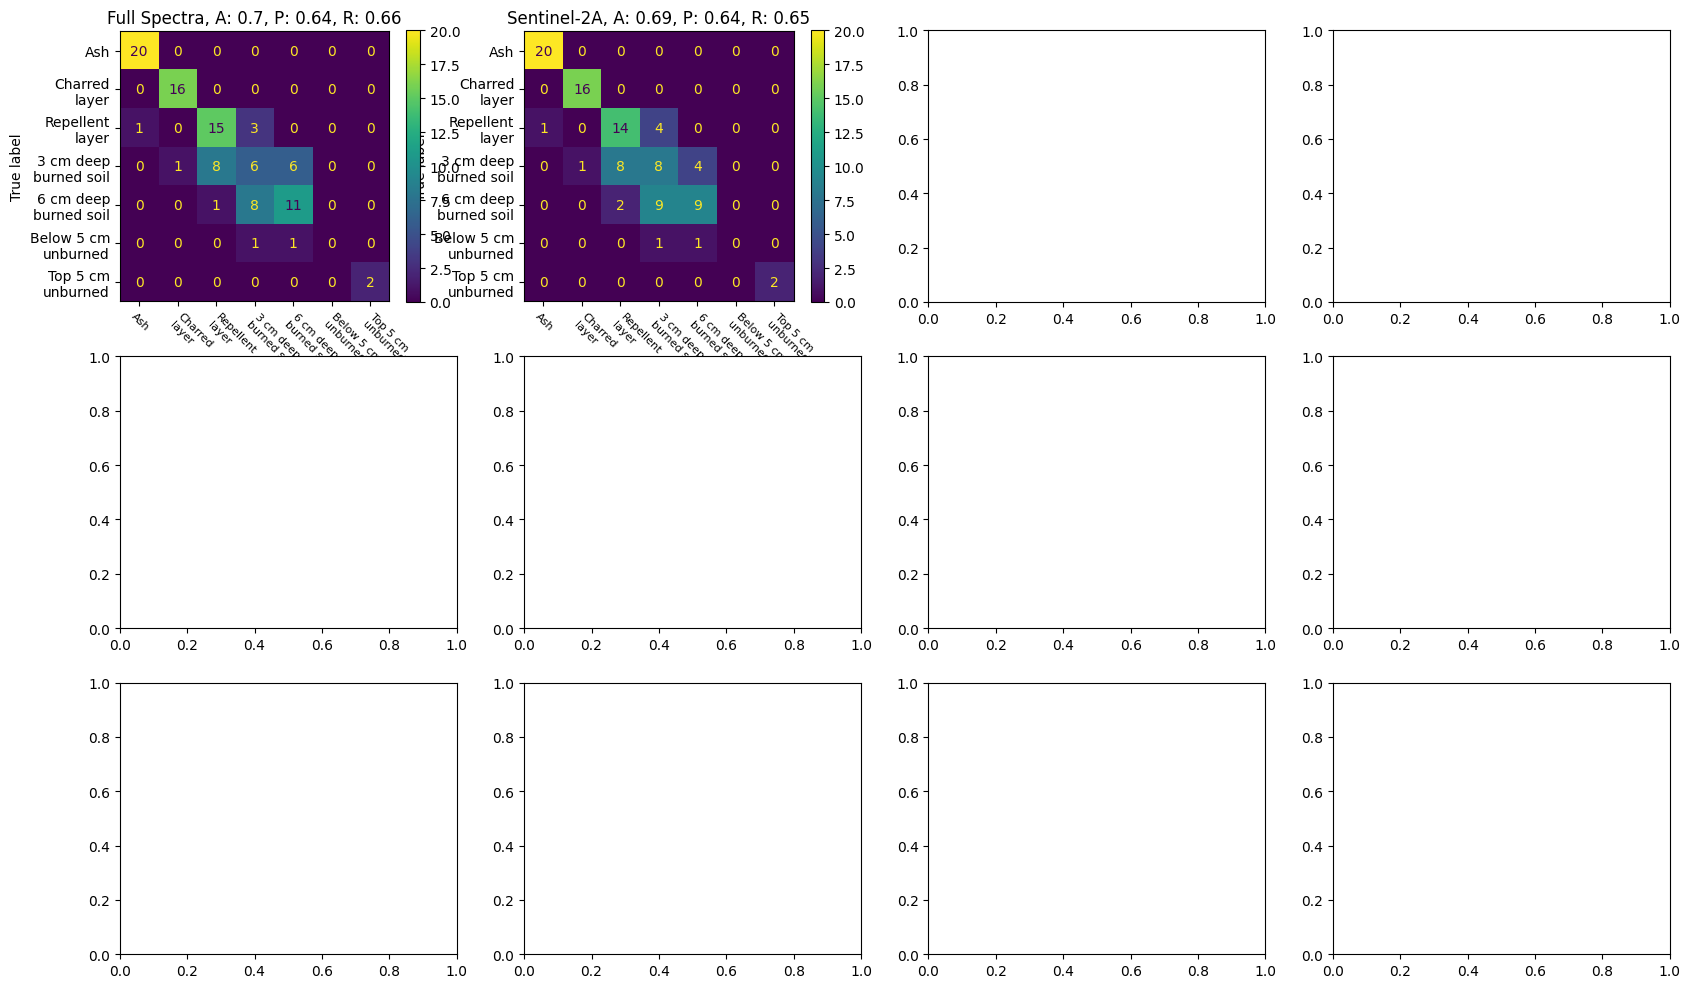

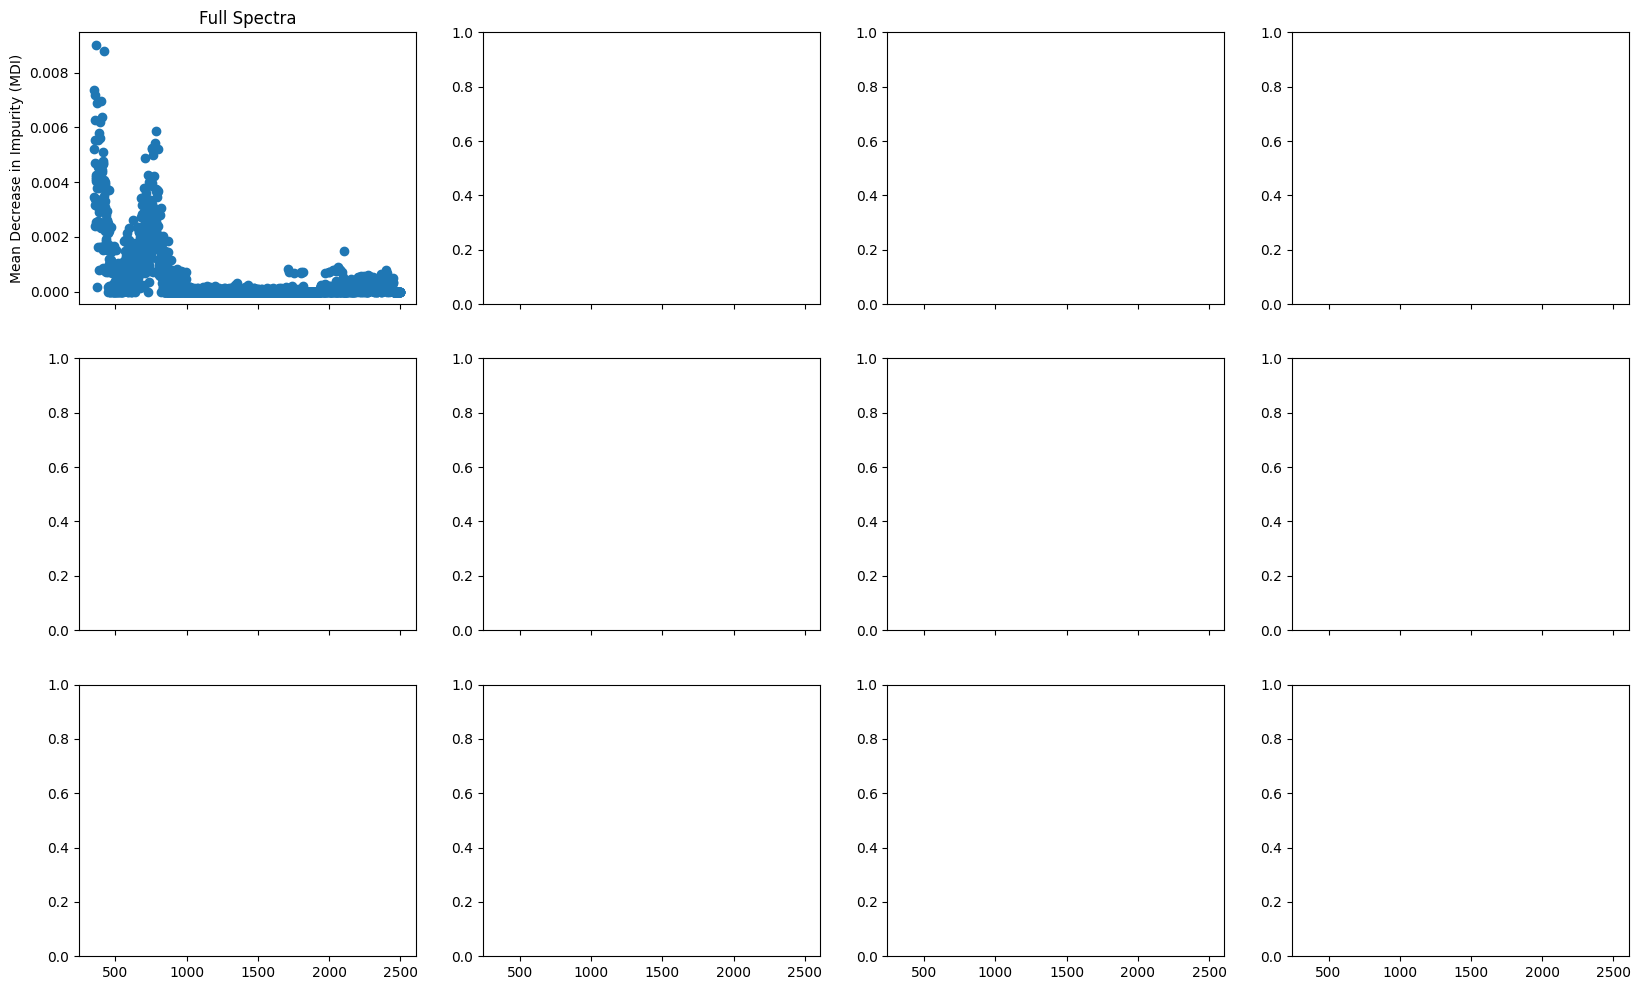

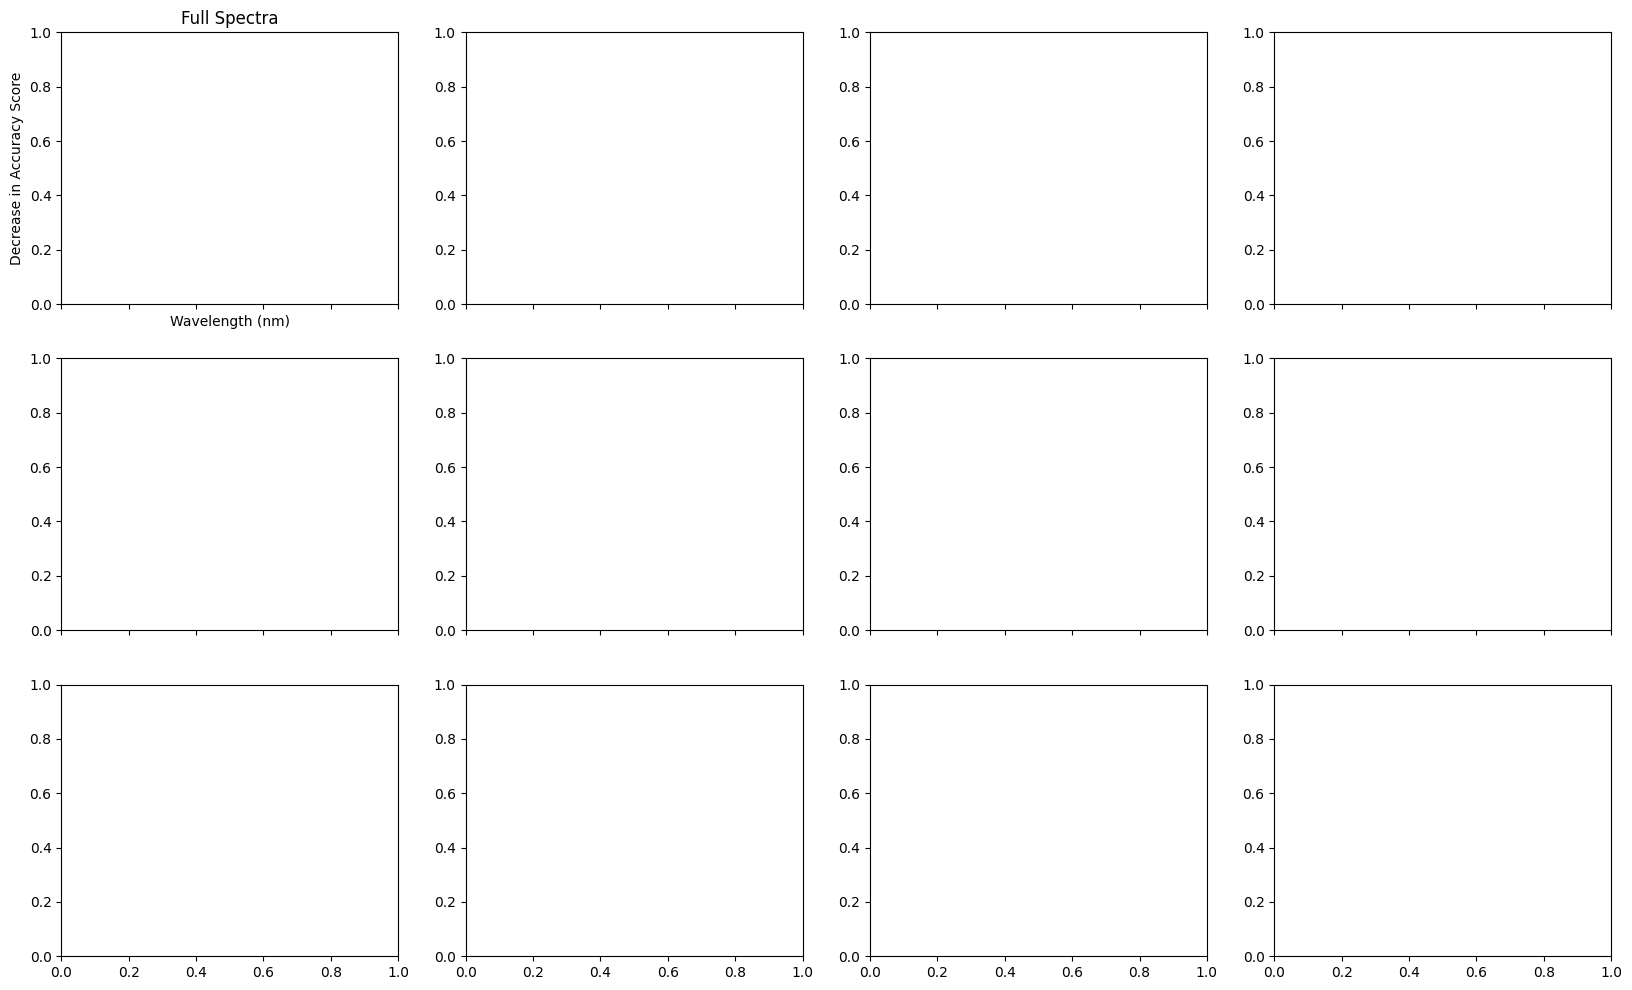

In [2]:
labels =    ['Ash',
             'Charred layer',
             'Repellent layer',
             '3 cm deep burned soil',
             '6 cm deep burned soil',
             'Below 5 cm unburned',
             'Top 5 cm unburned']


# Read all-observation convolved csvs

resampled_data = {}

resampled_data['Full Spectra'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\all_observations.csv",
                          index_col=0)

spectra_rfc = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\all_observations.csv",
                          index_col=0)

resampled_data['Sentinel-2A'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_Sentinel_2A.csv", index_col='Sample Name')

resampled_data['Sentinel-2B'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_Sentinel_2B.csv", index_col='Sample Name')

resampled_data['Sentinel-2C'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_Sentinel_2C.csv", index_col='Sample Name')

resampled_data['Landsat ETM+'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_Landsat_ETM.csv", index_col='Sample Name')

resampled_data['Landsat OLI-TIRS'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_Landsat_OLI.csv", index_col='Sample Name')

resampled_data['HySpex Mjolnir'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_HySpexMjolnir.csv", index_col='Sample Name')

resampled_data['AVIRIS 3'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_AVIRIS3.csv", index_col='Sample Name')

resampled_data['AVIRIS 5'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_AVIRIS5.csv", index_col='Sample Name')

resampled_data['P4 Multispectral'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_P4Multispectral.csv", index_col='Sample Name')

resampled_data['Pika IR-L'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_PikaIR-L.csv", index_col='Sample Name')

resampled_data['Sentera 6X'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_Sentera6X.csv", index_col='Sample Name')


fig, axes  = plt.subplots(3,4, figsize=(20,12))
fig2, axes2  = plt.subplots(3,4, figsize=(20,12), sharex=True)
fig3, axes3 = plt.subplots(3,4, figsize=(20,12), sharex=True)

axes_flat = axes.flatten()
axes_flat2 = axes2.flatten()
axes_flat3 = axes3.flatten()

i=0

for key, data in resampled_data.items():
    ax = axes_flat[i]
    ax2 = axes_flat2[i]
    ax3 = axes_flat3[i]
    
    X = data.drop('Category', axis=1)
    y = data['Category']

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

    rf = RandomForestClassifier(
        n_estimators=500,
        max_depth=4,
        min_samples_leaf=4,
        min_samples_split=10,
        max_features="sqrt",
        max_samples=0.75,
        # class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    )
    rf.fit(X_train, y_train)

    # Test whether the model is good at predicting
    y_pred = rf.predict(X_test)

    # Create the confusion matrix
    cm = confusion_matrix(y_test, y_pred, labels=labels)
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels,
                            # cmap=plt.cm.Blues,
                            # normalize=True
                            ).plot(ax = ax)
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred, average='macro')
    recall = recall_score(y_test, y_pred, average='macro')

    ax.set_title(f'{key}, A: {accuracy}, P: {precision:.2f}, R: {recall:.2f}')
    print(f'{key} Accuracy: {accuracy}, Precision: {precision}, Recall: {recall}')

    # Customize x-axis labels
    x_labels = [textwrap.fill(label.get_text(), 12) for label in ax.get_xticklabels()]
    ax.set_xticklabels(x_labels, rotation=-45, ha="left", va='top', fontsize=8)

    # Customize y-axis labels
    y_labels = [textwrap.fill(label.get_text(), 12) for label in ax.get_yticklabels()]
    ax.set_yticklabels(y_labels, rotation=0, ha="right", fontsize=10)

    # ax.tick_params(direction='out', length=6, width=2, colors='k')

    # create offset in x direction
    dx, dy = -10, 0
    offset = ScaledTranslation(dx / fig.dpi, dy / fig.dpi, fig.dpi_scale_trans)

    # apply offset to all xticklabels
    for label in ax.xaxis.get_majorticklabels():
        label.set_transform(label.get_transform() + offset)

    
    ## MDI Feature Importance

    # Create a series containing feature importances from the model and feature names from the training data
    if key == 'Full Spectra':
        importances = pd.Series(rf.feature_importances_, index=X_train.columns.astype(float))
        importances.plot(ax=ax2, marker='o', linestyle='')#.sort_values(ascending=False).plot.bar()
    else:
        instrument_df = pd.read_excel(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\SRFs\CommonSensors.xlsx",
                                sheet_name=key, index_col='Band Name')
        wavelength = instrument_df['Wavelength (nm)']
        importances = pd.Series(rf.feature_importances_, index=wavelength)
        # print(importances)
        importances.plot(ax=ax2, marker='o', linestyle='')#.sort_values(ascending=False).plot.bar()


    # ## Permutation Feature Importance
    # result = permutation_importance(
    #     rf, X_test, y_test, n_repeats=10, random_state=42, n_jobs=2
    # )

    # if key == 'Full Spectra':
    #         importances = pd.Series(result.importances_mean, index=X_train.columns.astype(float))
    #         importances.plot(ax=ax3, marker='o', linestyle='')#.sort_values(ascending=False).plot.bar()
    # else:
    #     instrument_df = pd.read_excel(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\SRFs\CommonSensors.xlsx",
    #                             sheet_name=key, index_col='Band Name')
    #     wavelength = instrument_df['Wavelength (nm)']
    #     importances = pd.Series(result.importances_mean, index=wavelength)
    #     # print(importances)
    #     importances.plot(ax=ax3, marker='o', linestyle='')#.sort_values(ascending=False).plot.bar()

    ax2.set_title(f'{key}')
    ax2.set_xlabel('Wavelength (nm)')
    ax2.set_ylabel('Mean Decrease in Impurity (MDI)')

    ax3.set_title(f'{key}')
    ax3.set_xlabel('Wavelength (nm)')
    ax3.set_ylabel('Decrease in Accuracy Score')

    print(f"RF train accuracy: {rf.score(X_train, y_train):.3f}")
    print(f"RF test accuracy: {rf.score(X_test, y_test):.3f}")

    i+=1






fig2.suptitle('Feature importances using MDI')

fig3.suptitle('Feature importances using Permutation')

fig.tight_layout()
fig2.tight_layout()
fig3.tight_layout()

# plt.savefig(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\rfc.jpg", dpi=300)


In [ ]:
## All samples + sample types
labels =    ['Ash',
             'Charred layer',
             'Repellent layer',
             '3 cm deep burned soil',
             '6 cm deep burned soil',
             'Below 5 cm unburned',
             'Top 5 cm unburned']

label_dict = {
    'Ash':'Ash',
    'Charred layer':'Charred layer',
    'Repellent layer':'Repellent layer',
    '3 cm deep burned soil':'3 cm deep burned soil',
    '6 cm deep burned soil':'6 cm deep burned soil',
    'Below 5 cm unburned':'Below 5 cm unburned',
    'Top 5 cm unburned':'Top 5 cm unburned',
}


## Combine soils into two categories
# labels = ['Ash',
#           'Charred layer',
#           'Burned soil',
#           'Unburned soil'
#           ]

# label_dict = {
#     'Ash':'Ash',
#     'Charred layer':'Charred layer',
#     'Repellent layer':'Burned soil',
#     '3 cm deep burned soil':'Burned soil',
#     '6 cm deep burned soil':'Burned soil',
#     'Below 5 cm unburned':'Unburned soil',
#     'Top 5 cm unburned':'Unburned soil'
# }


# ## Drop non-surface soils
# labels = ['Ash',
#           'Charred layer',
#           'Repellent layer',
#           'Unburned surface soil'
#           ]

# label_dict = {
#     'Ash':'Ash',
#     'Charred layer':'Charred layer',
#     'Repellent layer':'Repellent layer',
#     '3 cm deep burned soil':np.nan,
#     '6 cm deep burned soil':np.nan,
#     'Below 5 cm unburned':np.nan,
#     'Top 5 cm unburned':'Unburned soil'
# }


# Read all-observation convolved csvs

resampled_data = {}

resampled_data['Full Spectra'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\all_observations.csv",
                          index_col=0)

spectra_rfc = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\all_observations.csv",
                          index_col=0)

resampled_data['Sentinel-2A'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_Sentinel_2A.csv", index_col='Sample Name')


## Dropped since their responses are nearly identical to Sentinel-2A
resampled_data['Sentinel-2B'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_Sentinel_2B.csv", index_col='Sample Name')
resampled_data['Sentinel-2C'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_Sentinel_2C.csv", index_col='Sample Name')

resampled_data['Landsat ETM+'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_Landsat_ETM.csv", index_col='Sample Name')

resampled_data['Landsat OLI-TIRS'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_Landsat_OLI.csv", index_col='Sample Name')

resampled_data['HySpex Mjolnir'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_HySpexMjolnir.csv", index_col='Sample Name')

resampled_data['AVIRIS 3'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_AVIRIS3.csv", index_col='Sample Name')

resampled_data['AVIRIS 5'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_AVIRIS5.csv", index_col='Sample Name')

resampled_data['P4 Multispectral'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_P4Multispectral.csv", index_col='Sample Name')

resampled_data['Pika IR-L'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_PikaIR-L.csv", index_col='Sample Name')

resampled_data['Sentera 6X'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_Sentera6X.csv", index_col='Sample Name')




for key, df in resampled_data.items():
    df = df.copy()
    df['Category'] = df['Category'].map(label_dict)
    df = df.dropna(axis=0, how='any', subset=['Category'])
    resampled_data[key] = df



# Separate features and target
y = resampled_data['Full Spectra']['Category'].values

datasets = {
    key:df.drop(columns=['Category']).values for key,df in resampled_data.items()
}

# 2. Freeze exact train/test row indices once
#### Switch back to n_repeats=10
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
frozen_splits = list(cv.split(datasets["Full Spectra"], y))

# 3. Evaluate all datasets on the exact same sample splits
rf = RandomForestClassifier(
    n_estimators=500,   # can set to 500 for more precision
    max_depth=8,        #= Varied between 4-10, 8 is best* =#
    min_samples_leaf=5,
    min_samples_split=10,
    max_features="sqrt",
    max_samples=0.65,
    # class_weight="balanced_subsample",
    random_state=42,
    n_jobs=1
)

scoring = {"bal_acc": "balanced_accuracy", "macro_f1": "f1_macro", "log_loss": "neg_log_loss"}


y

<StringArray>
['6 cm deep burned soil', '6 cm deep burned soil', '6 cm deep burned soil',
 '6 cm deep burned soil', '6 cm deep burned soil', '6 cm deep burned soil',
 '6 cm deep burned soil', '6 cm deep burned soil', '6 cm deep burned soil',
 '6 cm deep burned soil',
 ...
   'Below 5 cm unburned',     'Top 5 cm unburned',     'Top 5 cm unburned',
     'Top 5 cm unburned',     'Top 5 cm unburned',     'Top 5 cm unburned',
     'Top 5 cm unburned',     'Top 5 cm unburned',     'Top 5 cm unburned',
     'Top 5 cm unburned']
Length: 497, dtype: str

In [ ]:
results = {}

for name, X_data in datasets.items():
    X_f32 = X_data.astype(np.float32)  
    res = cross_validate(rf, X_f32, y, cv=frozen_splits, 
                         scoring=scoring, return_train_score=True,
                         n_jobs=-1)
    results[name] = res
    print(f"=== {name} ({X_data.shape[1]} features) ===")
    print(f"  Val Macro F1:     {res['test_macro_f1'].mean():.4f} ± {res['test_macro_f1'].std():.4f} "
          f"(Train: {res['train_macro_f1'].mean():.4f})")
    print(f"  Val Balanced Acc: {res['test_bal_acc'].mean():.4f} ± {res['test_bal_acc'].std():.4f}")
    print(f"  Val Log Loss:     {-res['test_log_loss'].mean():.4f}\n")

=== Full Spectra (2151 features) ===
  Val Macro F1:     0.9676 ± 0.0230 (Train: 0.9786)
  Val Balanced Acc: 0.9728 ± 0.0153
  Val Log Loss:     0.1427

=== Sentinel-2A (12 features) ===
  Val Macro F1:     0.9706 ± 0.0161 (Train: 0.9772)
  Val Balanced Acc: 0.9707 ± 0.0163
  Val Log Loss:     0.2189

=== Sentinel-2B (12 features) ===
  Val Macro F1:     0.9709 ± 0.0160 (Train: 0.9773)
  Val Balanced Acc: 0.9709 ± 0.0162
  Val Log Loss:     0.2184

=== Sentinel-2C (12 features) ===
  Val Macro F1:     0.9706 ± 0.0161 (Train: 0.9772)
  Val Balanced Acc: 0.9707 ± 0.0163
  Val Log Loss:     0.2085

=== Landsat ETM+ (7 features) ===
  Val Macro F1:     0.9692 ± 0.0173 (Train: 0.9695)
  Val Balanced Acc: 0.9702 ± 0.0163
  Val Log Loss:     0.1674

=== Landsat OLI-TIRS (8 features) ===
  Val Macro F1:     0.9640 ± 0.0202 (Train: 0.9753)
  Val Balanced Acc: 0.9642 ± 0.0199
  Val Log Loss:     0.1693

=== HySpex Mjolnir (421 features) ===
  Val Macro F1:     0.9732 ± 0.0146 (Train: 0.9785)
  V

In [10]:
configs = {
    "Current (d=7, leaf=4)": dict(max_depth=7, min_samples_leaf=4, max_samples=0.75),
    "Slightly Stricter (d=7, leaf=5, sub=0.65)": dict(max_depth=7, min_samples_leaf=5, max_samples=0.65),
    "Deeper + Safer Leaf (d=8, leaf=5, sub=0.65)": dict(max_depth=8, min_samples_leaf=5, max_samples=0.65),
    "(d=9, leaf=5, sub=0.65)": dict(max_depth=9, min_samples_leaf=5, max_samples=0.65),
    "(d=10, leaf=5, sub=0.65)": dict(max_depth=10, min_samples_leaf=5, max_samples=0.65),
    "(d=8, leaf=4, sub=0.65)": dict(max_depth=8, min_samples_leaf=4, max_samples=0.65),

}

test_sensors = ["Full Spectra", "Sentinel-2A", "P4 Multispectral"]

for cfg_name, params in configs.items():
    print(f"=== {cfg_name} ===")
    rf_test = RandomForestClassifier(
        n_estimators=150,
        min_samples_split=10,
        max_features="sqrt",
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=1,
        **params
    )
    for s_name in test_sensors:
        res = cross_validate(
            rf_test, datasets[s_name].astype(np.float32), y,
            cv=frozen_splits, scoring=scoring, return_train_score=True, n_jobs=-1
        )
        print(f"  {s_name:<18} Val F1: {res['test_macro_f1'].mean():.4f} "
              f"(Train: {res['train_macro_f1'].mean():.4f}) | LogLoss: {-res['test_log_loss'].mean():.4f}")


=== Current (d=7, leaf=4) ===
  Full Spectra       Val F1: 0.8794 (Train: 0.9302) | LogLoss: 0.2547
  Sentinel-2A        Val F1: 0.8780 (Train: 0.9333) | LogLoss: 0.2506
  P4 Multispectral   Val F1: 0.8418 (Train: 0.9021) | LogLoss: 0.3628
=== Slightly Stricter (d=7, leaf=5, sub=0.65) ===
  Full Spectra       Val F1: 0.8793 (Train: 0.9164) | LogLoss: 0.2667
  Sentinel-2A        Val F1: 0.8744 (Train: 0.9244) | LogLoss: 0.2682
  P4 Multispectral   Val F1: 0.8385 (Train: 0.8831) | LogLoss: 0.3564
=== Deeper + Safer Leaf (d=8, leaf=5, sub=0.65) ===
  Full Spectra       Val F1: 0.8793 (Train: 0.9164) | LogLoss: 0.2667
  Sentinel-2A        Val F1: 0.8737 (Train: 0.9259) | LogLoss: 0.2675
  P4 Multispectral   Val F1: 0.8397 (Train: 0.8853) | LogLoss: 0.3605
=== (d=9, leaf=5, sub=0.65) ===
  Full Spectra       Val F1: 0.8793 (Train: 0.9164) | LogLoss: 0.2667
  Sentinel-2A        Val F1: 0.8737 (Train: 0.9261) | LogLoss: 0.2674
  P4 Multispectral   Val F1: 0.8386 (Train: 0.8868) | LogLoss: 0.3

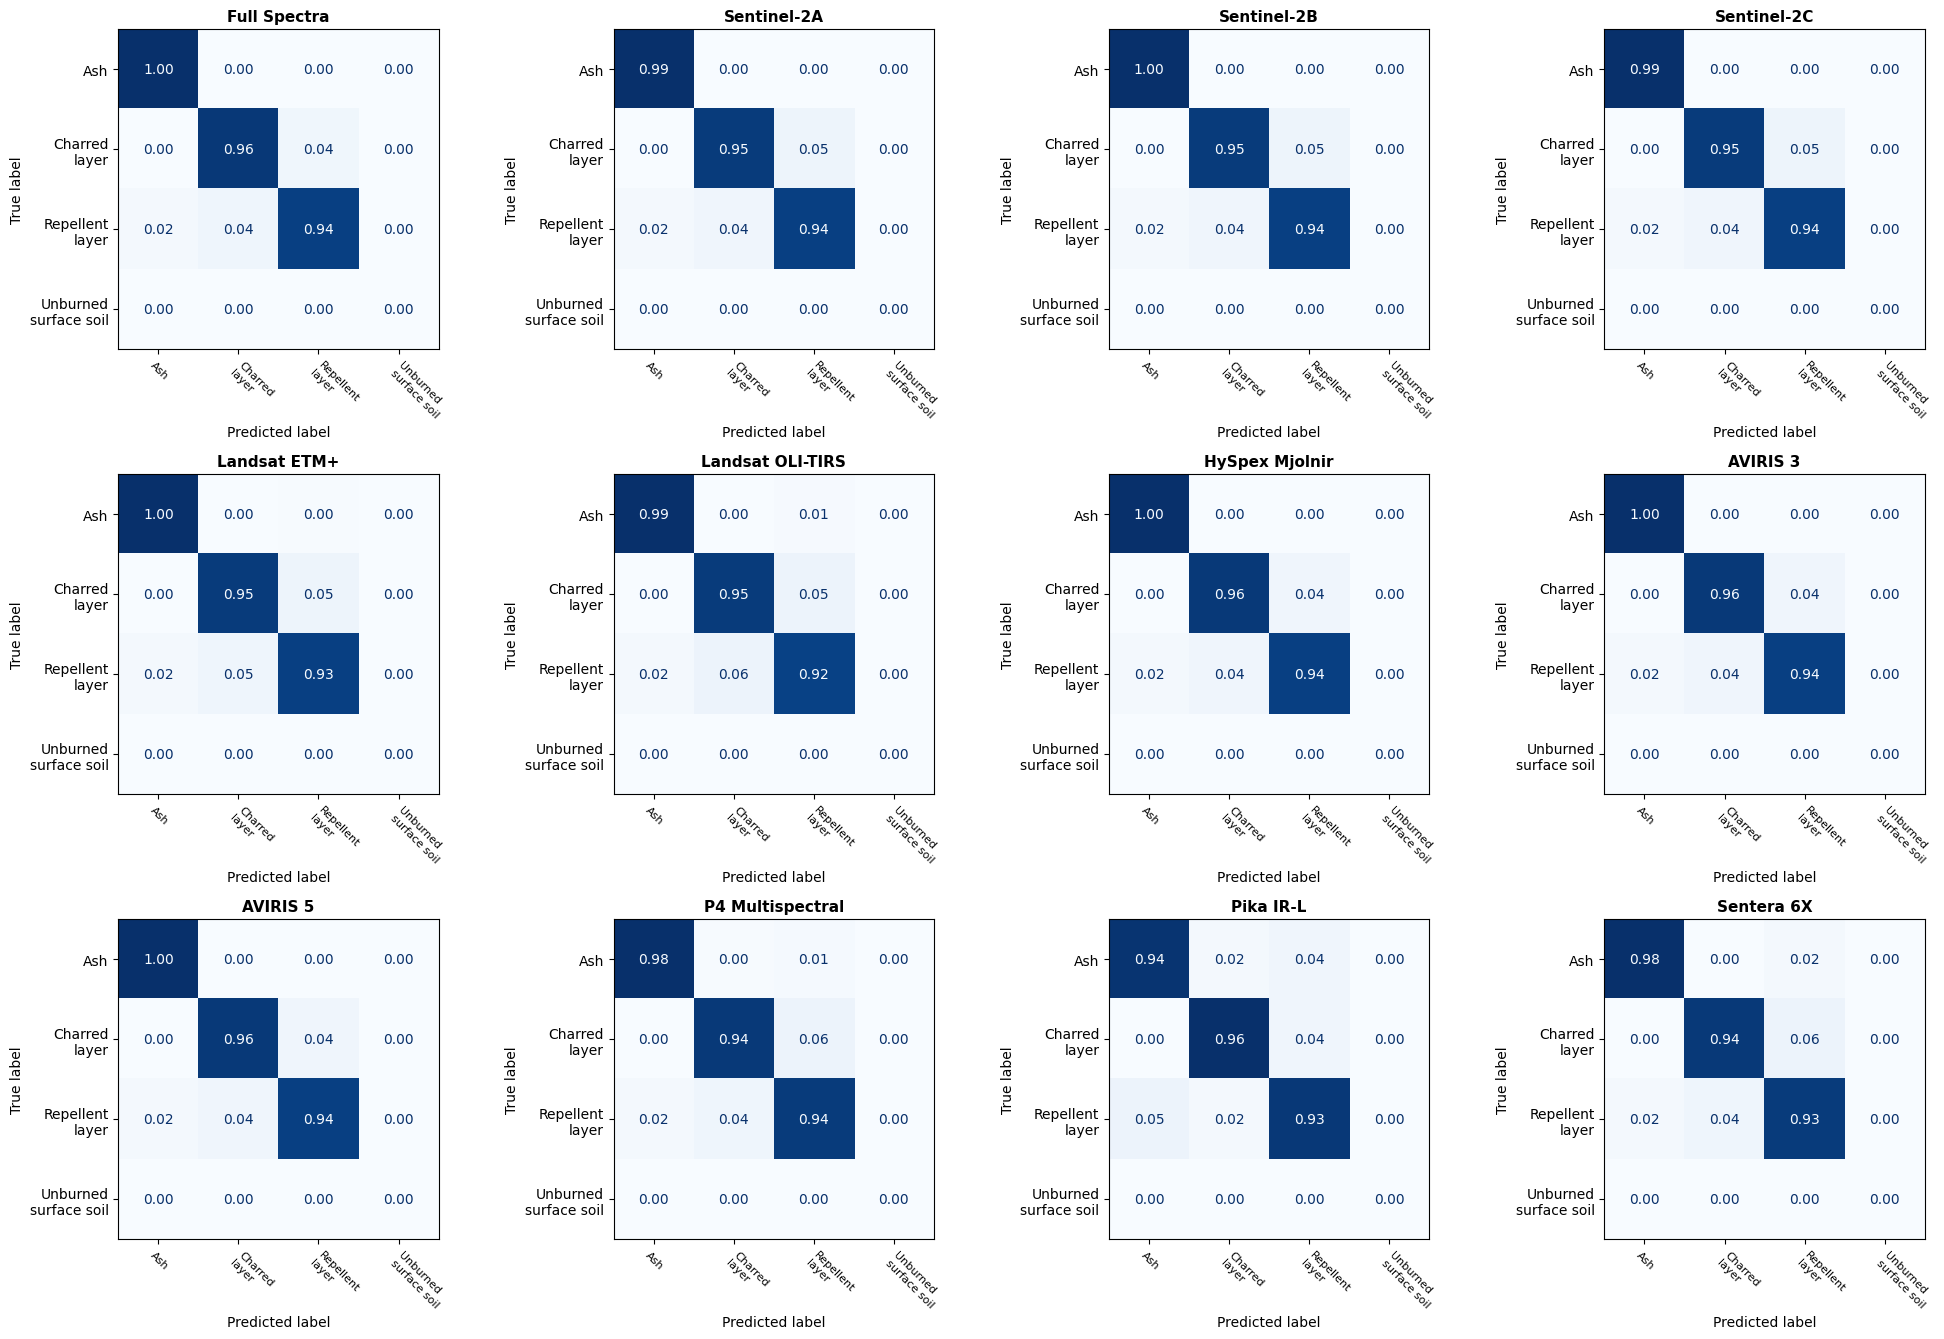

In [ ]:
# Ensure consistent class ordering across all sensors
class_labels = labels
conf_matrices = {}


for name, X_data in datasets.items():
    X_f32 = X_data.astype(np.float32)
    
    # Run cross_validate with return_estimator=True so we don't fit twice
    res = cross_validate(
        rf,
        X_f32,
        y,
        cv=frozen_splits,
        scoring=scoring,
        return_train_score=True,
        return_estimator=True,
        n_jobs=-1
    )
    
    # Collect out-of-fold predictions across all 50 folds
    y_true_all = []
    y_pred_all = []
    for est, (_, test_idx) in zip(res["estimator"], frozen_splits):
        y_true_all.append(y[test_idx])
        y_pred_all.append(est.predict(X_f32[test_idx]))
        
    y_true_all = np.concatenate(y_true_all)
    y_pred_all = np.concatenate(y_pred_all)
    
    # Row-normalized confusion matrix (shows recall % per true class)
    cm_norm = confusion_matrix(y_true_all, y_pred_all, labels=class_labels, normalize="true")
    conf_matrices[name] = cm_norm


# Plot all confusion matrices in a clean grid
n_sensors = len(conf_matrices)
cols = 4
rows = int(np.ceil(n_sensors / cols))

fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4.5 * rows))
axes = axes.flatten()

for idx, (name, cm) in enumerate(conf_matrices.items()):
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels)
    disp.plot(ax=axes[idx], cmap="Blues", values_format=".2f", colorbar=False)
    axes[idx].set_title(name, fontsize=11, fontweight="bold")
    axes[idx].tick_params(axis="x", rotation=45)

    # Customize x-axis labels
    x_labels = [textwrap.fill(label.get_text(), 12) for label in axes[idx].get_xticklabels()]
    axes[idx].set_xticklabels(x_labels, rotation=-45, ha="left", va='top', fontsize=8)

    # Customize y-axis labels
    y_labels = [textwrap.fill(label.get_text(), 12) for label in axes[idx].get_yticklabels()]
    axes[idx].set_yticklabels(y_labels, rotation=0, ha="right", fontsize=10)

    # create offset in x direction
    dx, dy = -10, 0
    offset = ScaledTranslation(dx / fig.dpi, dy / fig.dpi, fig.dpi_scale_trans)

    # apply offset to all xticklabels
    for label in axes[idx].xaxis.get_majorticklabels():
        label.set_transform(label.get_transform() + offset)

# Hide any unused subplot boxes
for idx in range(n_sensors, len(axes)):
    axes[idx].axis("off")

plt.tight_layout()
plt.savefig(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\RFC_CM_combined.jpg", dpi=300)
plt.show()


In [68]:
test_idx

array([  4,   5,   9,  10,  12,  15,  23,  33,  34,  38,  39,  44,  66,
        68,  70,  71,  73,  87,  93,  94,  99, 100, 107, 112, 125, 129,
       141, 150, 164, 165, 166, 171, 175, 179, 183, 191, 194, 195, 200,
       206, 211, 215, 218, 219, 220, 221, 225, 227, 236, 251, 262, 276,
       279, 281, 283, 293, 297, 300, 305, 311, 316, 317, 324, 330, 332,
       335, 336, 339, 341, 343, 350, 351, 357, 358, 361, 374, 382, 392,
       394, 397, 400, 401, 407, 413, 420, 435, 437, 438, 448, 449, 451,
       452, 457, 459, 462, 465, 488, 489, 490, 493])

In [9]:


# 1. Print exact class counts and the full row of predictions for 'ash'
print("Class counts:\n", pd.Series(y).value_counts(), "\n")

ash_idx = list(class_labels).index("Ash")
ash_row = pd.Series(conf_matrices["Full Spectra"][ash_idx], index=class_labels)
print("Where 'Ash' samples are being predicted:\n", ash_row.sort_values(ascending=False))


Class counts:
 3 cm deep burned soil    107
Ash                      100
6 cm deep burned soil     98
Repellent layer           96
Charred layer             79
Top 5 cm unburned          9
Below 5 cm unburned        8
Name: count, dtype: int64 

Where 'Ash' samples are being predicted:
 Ash                      0.996
Charred layer            0.002
Repellent layer          0.002
Unburned surface soil    0.000
dtype: float64


In [47]:
full_recalls = pd.Series(np.diag(conf_matrices["Full Spectra"]), index=class_labels)
s2_recalls = pd.Series(np.diag(conf_matrices["Sentinel-2A"]), index=class_labels)
p4_recalls = pd.Series(np.diag(conf_matrices["P4 Multispectral"]), index=class_labels)

recall_table = pd.DataFrame({
    "Count": pd.Series(y).value_counts(),
    "Full Spectra": full_recalls,
    "Sentinel-2A": s2_recalls,
    "P4 Multispectral": p4_recalls,
}).sort_values("Count", ascending=False)

print(recall_table.round(3))


                       Count  Full Spectra  Sentinel-2A  P4 Multispectral
3 cm deep burned soil    107         0.581        0.542             0.428
Ash                      100         0.998        1.000             0.982
6 cm deep burned soil     98         0.758        0.715             0.557
Repellent layer           96         0.676        0.692             0.691
Charred layer             79         0.958        0.956             0.948
Top 5 cm unburned          9         0.889        0.667             0.567
Below 5 cm unburned        8         0.000        0.000             0.000


## Dealing with colinearity

Baseline accuracy on test data: 0.78


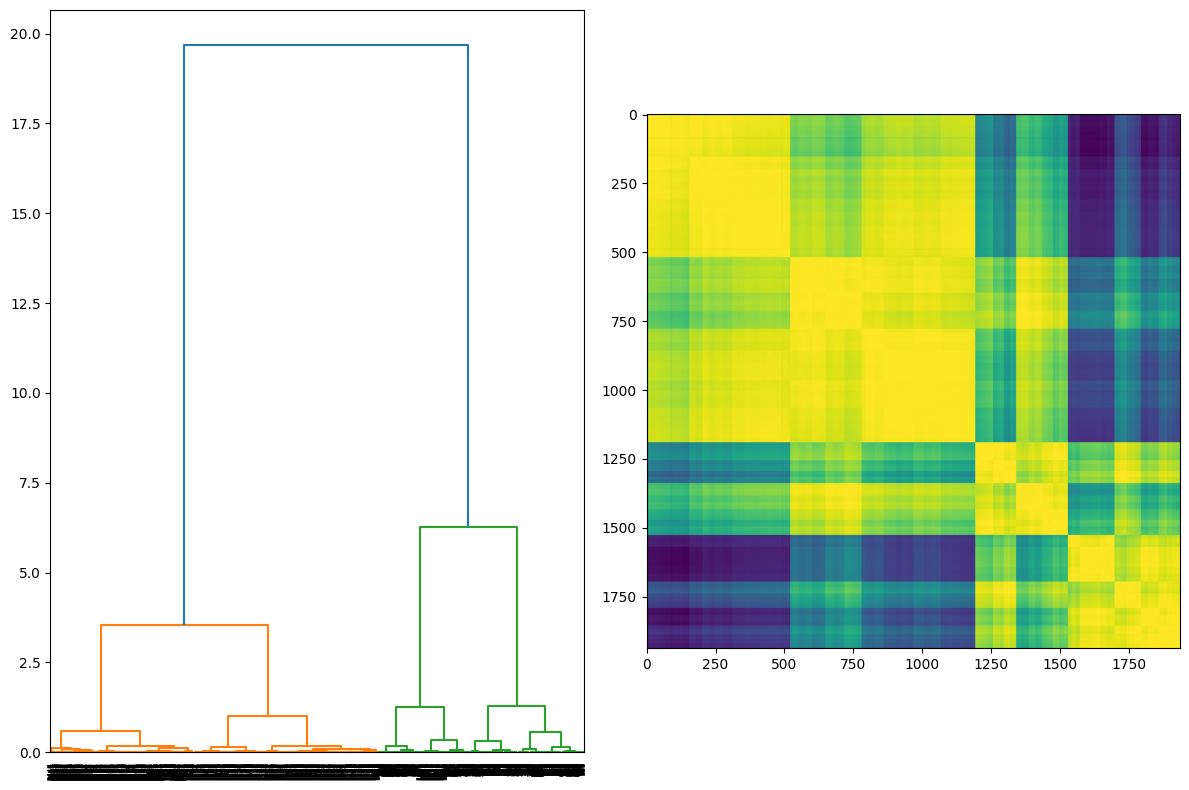

In [4]:
from sklearn.datasets import load_breast_cancer
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

# X, y = load_breast_cancer(return_X_y=True, as_frame=True)
data = resampled_data['Full Spectra']
X = data.drop('Category', axis=1)
X = X.dropna(axis=1)
y = data['Category']

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

clf = RandomForestClassifier(n_estimators=100, random_state=42)
clf.fit(X_train, y_train)
print(f"Baseline accuracy on test data: {clf.score(X_test, y_test):.2}")

from scipy.cluster import hierarchy
from scipy.spatial.distance import squareform
from scipy.stats import spearmanr

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 8))
corr = spearmanr(X).correlation

# Ensure the correlation matrix is symmetric
corr = (corr + corr.T) / 2
np.fill_diagonal(corr, 1)

# We convert the correlation matrix to a distance matrix before performing
# hierarchical clustering using Ward's linkage.
distance_matrix = 1 - np.abs(corr)
distance_matrix = np.round(1 - np.abs(corr), 10)
dist_linkage = hierarchy.ward(squareform(distance_matrix))
dendro = hierarchy.dendrogram(
    dist_linkage, labels=X.columns.to_list(), ax=ax1, leaf_rotation=90
)
dendro_idx = np.arange(0, len(dendro["ivl"]))

ax2.imshow(corr[dendro["leaves"], :][:, dendro["leaves"]])
# ax2.set_xticks(dendro_idx)
# ax2.set_yticks(dendro_idx)
# ax2.set_xticklabels(dendro["ivl"], rotation="vertical", fontsize=1)
# ax2.set_yticklabels(dendro["ivl"], fontsize=1)
_ = fig.tight_layout()

In [5]:
from collections import defaultdict

cluster_ids = hierarchy.fcluster(dist_linkage, 1, criterion="distance")
cluster_id_to_feature_ids = defaultdict(list)
for idx, cluster_id in enumerate(cluster_ids):
    cluster_id_to_feature_ids[cluster_id].append(idx)
selected_features = [v[0] for v in cluster_id_to_feature_ids.values()]
selected_features_names = X.columns[selected_features]

X_train_sel = X_train[selected_features_names]
X_test_sel = X_test[selected_features_names]

clf_sel = RandomForestClassifier(n_estimators=100, random_state=42)
clf_sel.fit(X_train_sel, y_train)
print(
    "Baseline accuracy on test data with features removed:"
    f" {clf_sel.score(X_test_sel, y_test):.2}"
)

Baseline accuracy on test data with features removed: 0.74


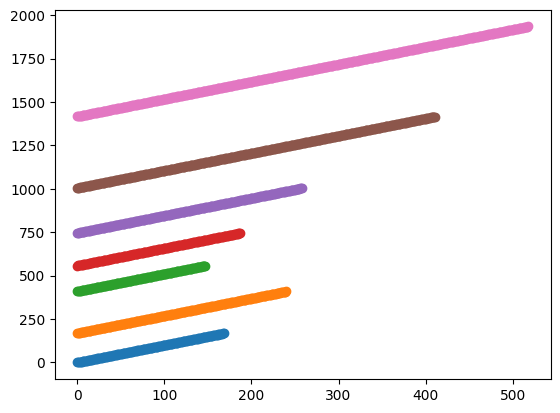

In [19]:
for x in cluster_id_to_feature_ids.values():
    plt.plot(x, linestyle='',marker='o')

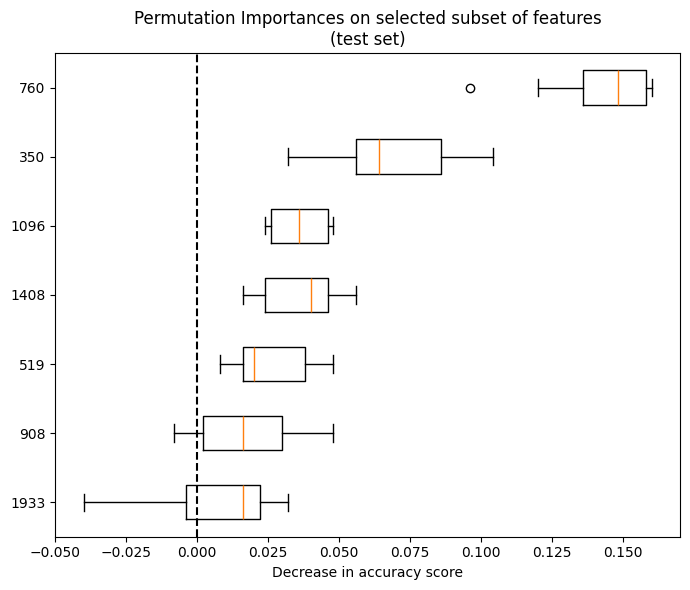

In [30]:
import matplotlib

from sklearn.inspection import permutation_importance
from sklearn.utils.fixes import parse_version


def plot_permutation_importance(clf, X, y, ax):
    result = permutation_importance(clf, X, y, n_repeats=10, random_state=42, n_jobs=2)
    perm_sorted_idx = result.importances_mean.argsort()

    # `labels` argument in boxplot is deprecated in matplotlib 3.9 and has been
    # renamed to `tick_labels`. The following code handles this, but as a
    # scikit-learn user you probably can write simpler code by using `labels=...`
    # (matplotlib < 3.9) or `tick_labels=...` (matplotlib >= 3.9).
    tick_labels_parameter_name = (
        "tick_labels"
        if parse_version(matplotlib.__version__) >= parse_version("3.9")
        else "labels"
    )
    tick_labels_dict = {tick_labels_parameter_name: X.columns[perm_sorted_idx]}
    # `vert` was deprecated in matplotlib 3.11 and is replaced by `orientation`,
    # which is available since matplotlib 3.10. The following code handles this,
    # but as a scikit-learn user you probably can write simpler code by using
    # `vert=False` (matplotlib < 3.11) or `orientation="horizontal"`
    # (matplotlib >= 3.10).
    orientation_dict = (
        {"orientation": "horizontal"}
        if parse_version(matplotlib.__version__) >= parse_version("3.10")
        else {"vert": False}
    )
    ax.boxplot(
        result.importances[perm_sorted_idx].T, **orientation_dict, **tick_labels_dict
    )
    ax.axvline(x=0, color="k", linestyle="--")
    return ax

fig, ax = plt.subplots(figsize=(7, 6))
plot_permutation_importance(clf_sel, X_test_sel, y_test, ax)
ax.set_title("Permutation Importances on selected subset of features\n(test set)")
ax.set_xlabel("Decrease in accuracy score")
ax.figure.tight_layout()
plt.show()

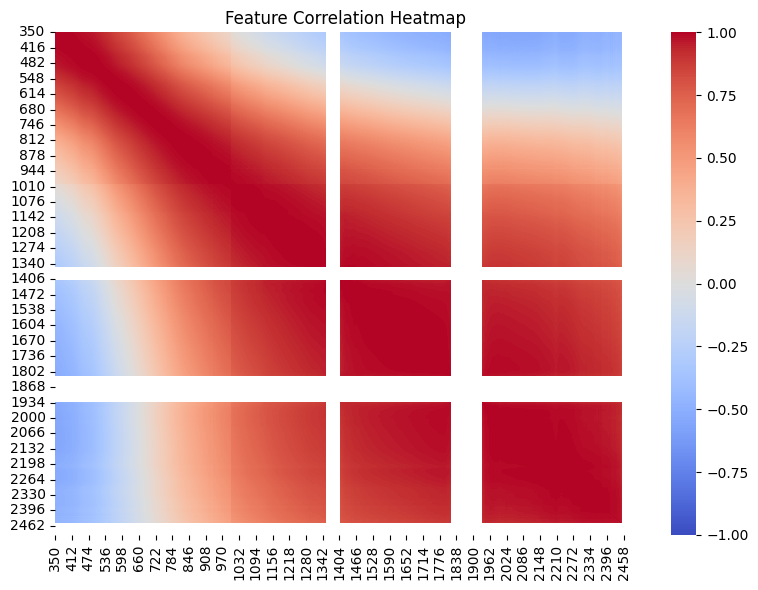

In [4]:
data = resampled_data['Full Spectra'].drop(columns=['Category'])

plt.figure(figsize=(8, 6))
sns.heatmap(data.corr(), annot=False, cmap='coolwarm', fmt='.2f',center = 0, 
                        vmax = 1, vmin = -1)
plt.title('Feature Correlation Heatmap')
plt.tight_layout()
plt.show()

In [18]:
param_dist = {
  'n_estimators': randint(100, 500),
  'max_depth': randint(3, 20),
  'min_samples_split': randint(2, 10),
  'min_samples_leaf': randint(1, 5)
}


# Create a random forest classifier
rf = RandomForestClassifier(random_state=42, n_jobs=-1)

# Use random search to find the best hyperparameters
rand_search = RandomizedSearchCV(
  rf, param_distributions=param_dist,
  n_iter=10, cv=5, scoring='accuracy',
  n_jobs=-1, random_state=42
  )

rand_search.fit(X_train, y_train)

# Create a variable for the best model
best_rf = rand_search.best_estimator_

# Print the best hyperparameters
print('Best hyperparameters:',  rand_search.best_params_)

Best hyperparameters: {'max_depth': 9, 'min_samples_leaf': 2, 'min_samples_split': 4, 'n_estimators': 314}


Accuracy: 0.81
Precision: 0.7328361344537815
Recall: 0.7348057644110275


c:\Users\nmmas\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


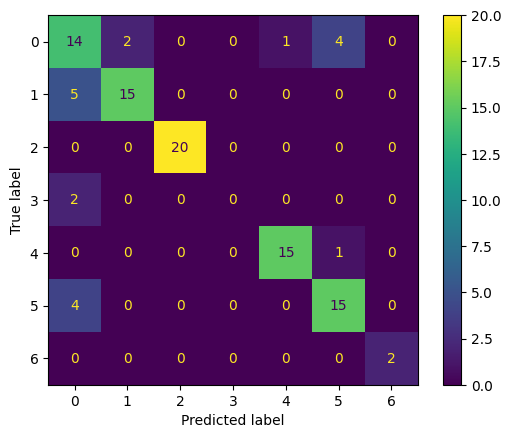

In [ ]:
# Generate predictions with the best model
y_pred = best_rf.predict(X_test)

# Create the confusion matrix
cm = confusion_matrix(y_test, y_pred)

ConfusionMatrixDisplay(confusion_matrix=cm).plot()

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='macro')
recall = recall_score(y_test, y_pred, average='macro')

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)

plt.title(f'{key}, Accuracy: {accuracy}')


<Axes: xlabel='Wavelength'>

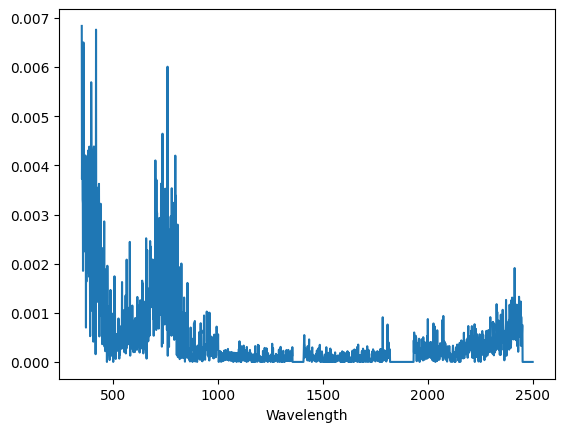

In [30]:
# Create a series containing feature importances from the model and feature names from the training data
importances = pd.Series(best_rf.feature_importances_, index=X_train.columns.astype(float))
importances.plot()#.sort_values(ascending=False).plot.bar()


## Save spectra means to .csv files

In [ ]:
## Save mean endmember spectra as .csvs
fname = r'C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\rf_obs_df.csv'

# for my_type,df in sorted_dic.items():
#     df[f'{my_type}_firemeans'].to_csv(fname+rf'\{my_type}_cleaned.csv')


# Read cleaned, averaged spectra csv files

In [3]:
## Read endmember spectra .csvs to a dictionary of df

reflectance_spectra = {}

fname = r'C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\Cleaned CSVs'

os.chdir(fname)
listdir = os.listdir()
listdir = [dir for dir in listdir if dir.endswith('.csv')]

for csv in listdir:
    df = pd.read_csv(filepath_or_buffer=fname+rf'\{csv}', index_col='Wavelength')
    name = lineformats[csv.split('_')[0]][1]
    reflectance_spectra[name] = df['mean']

spectra_df = pd.DataFrame.from_dict(reflectance_spectra)

spectra_df.plot(xlabel='Wavelength', ylabel='Reflectance')

fname = r'C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\cleaned_means.csv'
spectra_df.to_csv(fname)


KeyError: 'cleaned'

In [7]:
spectra_rfc.T.drop(['Category']).rename(index=(float)).index

Index([ 350.0,  351.0,  352.0,  353.0,  354.0,  355.0,  356.0,  357.0,  358.0,
        359.0,
       ...
       2491.0, 2492.0, 2493.0, 2494.0, 2495.0, 2496.0, 2497.0, 2498.0, 2499.0,
       2500.0],
      dtype='float64', length=2151)

In [ ]:
SRF_AVIRIS5 = pd.read_excel(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\CommonSensors.xlsx",
                           sheet_name='AVIRIS 5', index_col='Band Name')

SRF_AVIRIS5_round = SRF_AVIRIS5.round()
SRF_AVIRIS5_round

,Start (nm),End (nm)
Band Name,,
1,378.0,382.0
2,382.0,388.0
3,388.0,392.0
4,392.0,398.0
5,398.0,402.0
...,...,...
421,2478.0,2482.0
422,2482.0,2488.0
423,2488.0,2492.0


In [34]:
dict = {}

for band_name in SRF_AVIRIS5_round.index:
    dict[band_name] = spectra_rfc.T.drop(['Category']).rename(index=(float))[SRF_AVIRIS5_round['Start (nm)'][band_name]:SRF_AVIRIS5_round['End (nm)'][band_name]].mean()


rfc_AVIRIS3 = pd.DataFrame.from_dict(dict, orient='index').T#.plot(xlabel='AVIRIS 3 Band Name', ylabel='Reflectance')
rfc_AVIRIS3.insert(loc=0, column='Category', value=spectra_rfc['Category'])
rfc_AVIRIS3

,Category,1,2,3,4,5,6,7,8,9,...,416,417,418,419,420,421,422,423,424,425
Jul14-blue-1-repeated00000.asd.ref,6 cm deep burned soil,0.071806,0.073978,0.075814,0.078254,0.080532,0.082373,0.084489,0.086551,0.088839,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Jul14-blue-1-repeated00001.asd.ref,6 cm deep burned soil,0.071010,0.073651,0.075956,0.078282,0.080494,0.082316,0.084330,0.086838,0.089224,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Jul14-blue-1-repeated00002.asd.ref,6 cm deep burned soil,0.065985,0.068217,0.070370,0.072538,0.074368,0.076139,0.077988,0.080046,0.082353,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Jul14-blue-1-repeated00003.asd.ref,6 cm deep burned soil,0.059488,0.061719,0.063271,0.065404,0.066875,0.068527,0.070142,0.072082,0.073648,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Jul14-blue-1-repeated00004.asd.ref,6 cm deep burned soil,0.057339,0.059224,0.060750,0.062593,0.064304,0.065757,0.067205,0.068926,0.070751,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Jul18-unburned-top2in00004.asd.ref,Top 5 cm unburned,0.071603,0.073819,0.076365,0.078880,0.080654,0.082910,0.085357,0.087556,0.089951,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Jul18-unburned-top2in00005.asd.ref,Top 5 cm unburned,0.073497,0.075335,0.077797,0.080956,0.083491,0.085912,0.088808,0.091408,0.094105,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Jul18-unburned-top2in00006.asd.ref,Top 5 cm unburned,0.073877,0.076375,0.079053,0.081724,0.083250,0.085624,0.087934,0.090237,0.092874,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Jul18-unburned-top2in00007.asd.ref,Top 5 cm unburned,0.074447,0.076876,0.079453,0.082267,0.084238,0.086402,0.088492,0.090933,0.093642,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Convolve using FWHM

In [2]:

def resample_dataframe_spectra_sum(df_spectra, source_wl, target_centers, target_fwhms, target_mins, target_maxs, target_bands):
    """
    Resamples a pandas DataFrame of spectra to multiple target bands by Riemand sum
    and FWHM

    Parameters:
    -----------
    df_spectra : pd.DataFrame
        DataFrame of shape (N_pixels, N_source_bands). Each row is a spectrum.
        Columns should correspond sequentially to the source_wl array.
    source_wl : np.ndarray or list
        1D array of the original hyperspectral band center wavelengths.
    target_centers, target_fwhms, target_mins, target_maxs : lists or arrays
        Target sensor band specifications.
        
    Returns:
    --------
    df_resampled : pd.DataFrame
        A new DataFrame with the same index as the input, containing the target bands as columns.
    """
    # 1. Align data and extract the raw numpy matrix
    source_wl = np.asarray(source_wl)
    # Ensure we drop any metadata columns if they exist, or just grab the values
    spectra_matrix = df_spectra.values  # Shape: (P, S)
    
    # 2. Build the Spectral Response Function (SRF) Base Weight Matrix -> Shape: (S, T)
    sigmas = np.asarray(target_fwhms) / (2 * np.sqrt(2 * np.log(2)))
    delta_wl = source_wl[:, None] - np.asarray(target_centers)[None, :]
    weights = np.exp(-(delta_wl ** 2) / (2 * (sigmas[None, :] ** 2)))
    
    # Apply the min/max window filters
    mask = (source_wl[:, None] >= np.asarray(target_mins)[None, :]) & (source_wl[:, None] <= np.asarray(target_maxs)[None, :])
    weights = weights * mask  # Shape: (S, T)
    
    # 3. Handle NaNs: Find where data is missing in the DataFrame
    # nan_mask is True where data is valid, False where data is NaN
    nan_mask = ~np.isnan(spectra_matrix)  # Shape: (P, S)
    
    # 4. Compute NaN-safe weighted sum
    # Instead of standard np.dot, we nullify the weights where the specific pixel has a NaN.
    # We expand spectra_matrix to (P, S, 1) and weights to (1, S, T) to broadcast across all combinations
    safe_spectra = np.nan_to_num(spectra_matrix) # Replace NaNs with 0 temporarily for multiplication
    
    # Numerator: Weighted sum of valid data points
    # (P, S) dot (S, T) -> (P, T)
    weighted_sum = np.dot(safe_spectra, weights)
    
    # Denominator: Sum of weights ONLY for bands that actually had valid data for that pixel
    # nan_mask cast to float (1 for valid, 0 for NaN) multiplied by weights
    # (P, S) dot (S, T) -> (P, T)
    valid_weight_sums = np.dot(nan_mask.astype(float), weights)
    
    # Prevent divide-by-zero if a pixel is entirely NaN within a band's active window
    valid_weight_sums[valid_weight_sums == 0] = np.nan
    
    # 5. Calculate final resampled matrix
    resampled_matrix = weighted_sum / valid_weight_sums
    
    # 6. Reconstruct back into a clean Pandas DataFrame
    col_names = np.asarray(target_bands)
    df_resampled = pd.DataFrame(resampled_matrix.T, index=df_spectra.index, columns=col_names)
    
    return df_resampled
    


In [3]:

def resample_dataframe_spectra(df_spectra, source_wl, target_centers, target_fwhms, target_mins, target_maxs, target_bands):
    """
    Resamples a pandas DataFrame of spectra to multiple target bands by trapezoidal integral
    and FWHM
    
    Parameters:
    -----------
    df_spectra : pd.DataFrame
        DataFrame of shape (N_pixels, N_source_bands). Each row is a spectrum.
        Columns should correspond sequentially to the source_wl array.
    source_wl : np.ndarray or list
        1D array of the original hyperspectral band center wavelengths.
    target_centers, target_fwhms, target_mins, target_maxs : lists or arrays
        Target sensor band specifications.
        
    Returns:
    --------
    df_resampled : pd.DataFrame
        A new DataFrame with the same index as the input, containing the target bands as columns.
    """

    # 1. Align data and extract the raw numpy matrix
    source_wl = np.asarray(source_wl)
    # Ensure we drop any metadata columns if they exist, or just grab the values
    spectra_matrix = df_spectra.values  # Shape: (P, S)
    
    # 2. Build the Spectral Response Function (SRF) Base Weight Matrix -> Shape: (S, T)
    sigmas = np.asarray(target_fwhms) / (2 * np.sqrt(2 * np.log(2)))
    delta_wl = source_wl[:, None] - np.asarray(target_centers)[None, :]
    weights = np.exp(-(delta_wl ** 2) / (2 * (sigmas[None, :] ** 2)))
    
    # Apply the min/max window filters
    mask = (source_wl[:, None] >= np.asarray(target_mins)[None, :]) & (source_wl[:, None] <= np.asarray(target_maxs)[None, :])
    weights = weights * mask  # Shape: (S, T)
    weights = weights
    # weights = np.sum(weights, axis=1) # Creates a 1D array of weights to apply
    
    # 3. Handle NaNs: Find where data is missing in the DataFrame
    # nan_mask is True where data is valid, False where data is NaN
    nan_mask = ~np.isnan(spectra_matrix)  # Shape: (P, S)
    
    # 4. Compute NaN-safe weighted sum
    # Instead of standard np.dot, we nullify the weights where the specific pixel has a NaN.
    # We expand spectra_matrix to (P, S, 1) and weights to (1, S, T) to broadcast across all combinations
    safe_spectra = np.nan_to_num(spectra_matrix) # Replace NaNs with 0 temporarily for multiplication
    
    # Numerator: Weighted reflectance 3D array (integral of Ref*SRF)
    # (n, M, 1) * (1, M, N) -> (n, M, N)
    weighted_ref = weights[np.newaxis,...].T * safe_spectra.T[np.newaxis,...]
    numerator = np.trapezoid(weighted_ref, axis=1)

    # Denominator: Weights for each band (integral of SRF)
    denominator = np.trapezoid(weights, axis=0)
    
    resampled_matrix = numerator / denominator[..., np.newaxis]

    # Reconstruct back into a clean Pandas DataFrame
    col_names = np.asarray(target_bands)
    df_resampled = pd.DataFrame(resampled_matrix.T, index=df_spectra.index, columns=col_names)

    return df_resampled
    


In [4]:

def resample_dataframe_spectra_SRF(df_spectra, source_wl, target_wl, target_srf, target_bands):
    """
    Resamples a pandas DataFrame of spectra to multiple target bands using spectral response function
    
    Parameters:
    -----------
    df_spectra : pd.DataFrame
        DataFrame of shape (N_pixels, N_source_bands). Each row is a spectrum.
        Columns should correspond sequentially to the source_wl array.
    source_wl : np.ndarray or list
        1D array of the original hyperspectral band center wavelengths.
    target_wl, target_srf : lists or arrays
        Target sensor band specifications.
        
    Returns:
    --------
    df_resampled : pd.DataFrame
        A new DataFrame with the same index as the input, containing the target bands as columns.
    """

    # 1. Align data and extract the raw numpy matrix
    source_wl = np.asarray(source_wl)
    # Ensure we drop any metadata columns if they exist, or just grab the values
    spectra_matrix = df_spectra.values  # Shape: (P, S)
    
    # 2. Read spectral response function as weights
    weights = target_srf
    
    # 4. Compute NaN-safe weighted sum
    # Instead of standard np.dot, we nullify the weights where the specific pixel has a NaN.
    # We expand spectra_matrix to (P, S, 1) and weights to (1, S, T) to broadcast across all combinations
    safe_spectra = np.nan_to_num(spectra_matrix) # Replace NaNs with 0 temporarily for multiplication
    
    # Numerator: Weighted reflectance 3D array (integral of Ref*SRF)
    # (n, M, 1) * (1, M, N) -> (n, M, N)
    weighted_ref = weights[np.newaxis,...].T * safe_spectra.T[np.newaxis,...]
    numerator = np.trapezoid(weighted_ref, axis=1)



    # Denominator: Weights for each band (integral of SRF)
    denominator = np.trapezoid(weights, axis=0)
    
    resampled_matrix = numerator / denominator[..., np.newaxis]

    # Reconstruct back into a clean Pandas DataFrame
    col_names = np.asarray(target_bands)
    df_resampled = pd.DataFrame(resampled_matrix.T, index=df_spectra.index, columns=col_names)

    return df_resampled


In [ ]:
# # Target SRF for FWHM type sensors
# target_srf = pd.read_excel(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\CommonSensors.xlsx",
#                            sheet_name='Sentera 6X', index_col='Band Name')

# # Target SRF for Spectral Response type sensors
target_srf = pd.read_excel(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\SRFs\CommonSensors.xlsx",
                           sheet_name='Landsat 9 OLI SRF', index_col='Wavelength')


target_srf

,Band 1 - Ultra Blue (coastal/aerosol),Band 2 - Blue,Band 3 - Green,Band 4 – Red,Band 5 – NIR,Band 6 – SWIR 1,Band 7 – SWIR 2,Band 8 – Panchromatic
Wavelength,,,,,,,,
350,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
351,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
352,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
353,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
354,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...
2496,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2497,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2498,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


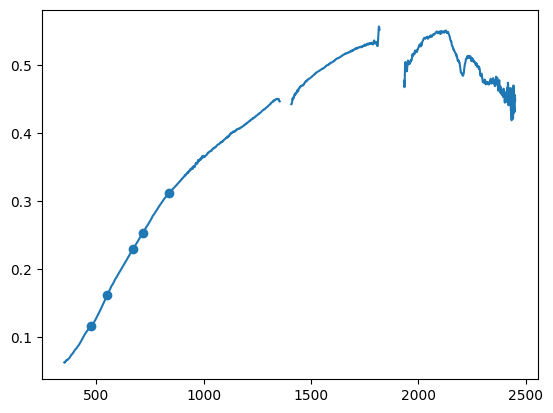

In [ ]:

# ============================================
# Create .csv for convolved FWHM type sensors
# ============================================

src_wl = spectra_rfc.drop(columns=['Category']).rename(columns=(int)).T.index
src_spectra = spectra_rfc.drop(columns=['Category']).rename(columns=(int))

# Define target sensor parameters (e.g., simulating a specific Sentinel or Landsat band)
target_center = target_srf['Wavelength (nm)']   # Center wavelength (nm)
target_fwhm = target_srf['FWHM']                # Full Width at Half Maximum (nm)
target_min = target_srf['Start (nm)']           # Hard lower bound limit (nm)
target_max = target_srf['End (nm)']             # Hard upper bound limit (nm)
target_bands = target_srf.index                 # Name of band


# Execute resampling
band_value = resample_dataframe_spectra(
        source_wl=src_wl,
        df_spectra=src_spectra,
        target_centers=target_center,
        target_fwhms=target_fwhm,
        target_mins=target_min,
        target_maxs=target_max,
        target_bands=target_bands
    )

plt.plot(src_wl, src_spectra.iloc[0])

plt.scatter(target_center, band_value.iloc[0])

fname = r'C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_Sentera6X.csv'
band_value.insert(loc=0, column='Category', value=spectra_rfc['Category'])
band_value.to_csv(fname)


# band_value

In [35]:

# ============================================
# Create .csv for convolved SRF type sensors
# ============================================

src_wl = spectra_rfc.drop(columns=['Category']).rename(columns=(int)).T.index
src_spectra = spectra_rfc.drop(columns=['Category']).rename(columns=(int))

# Define target sensor parameters (e.g., simulating a specific Sentinel or Landsat band)
target_wl = target_srf.index.to_list()          # Center wavelength (nm)
target_srf_vals = target_srf.values             # SRF
target_bands = target_srf.keys().to_list()      # Name of bands


# Execute resampling
band_value = resample_dataframe_spectra_SRF(
        source_wl=src_wl,
        df_spectra=src_spectra,
        target_wl=target_wl,
        target_srf=target_srf_vals,
        target_bands=target_bands
    )

# plt.plot(src_wl, src_spectra.iloc[0])

# plt.plot(target_wl, band_value.T[0,:,0])
# plt.plot(target_wl, band_value.T[0,:,1])
# plt.plot(target_wl, band_value.T[0,:,2])
# plt.plot(target_wl, band_value.T[0,:,3])
# plt.plot(target_wl, band_value.T[0,:,4])
# plt.plot(target_wl, band_value.T[0,:,5])
# plt.plot(target_wl, band_value.T[0,:,6])
# plt.plot(target_wl, band_value.T[0,:,7])
# plt.plot(target_wl, band_value.T[0,:,8])
# plt.plot(target_wl, band_value.T[0,:,9])
# plt.plot(target_wl, band_value.T[0,:,10])
# plt.plot(target_wl, band_value.T[0,:,11])
# plt.plot(target_wl, band_value.T[0,:,12])




fname = r'C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_Landsat_OLI.csv'
band_value.insert(loc=0, column='Category', value=spectra_rfc['Category'])
band_value.to_csv(fname)


band_value

,Category,Band 1 - Ultra Blue (coastal/aerosol),Band 2 - Blue,Band 3 - Green,Band 4 – Red,Band 5 – NIR,Band 6 – SWIR 1,Band 7 – SWIR 2,Band 8 – Panchromatic
Sample Name,,,,,,,,,
Jul14-blue-1-repeated00000.asd.ref,6 cm deep burned soil,0.101825,0.119570,0.168067,0.220553,0.320599,0.506649,0.514930,0.186226
Jul14-blue-1-repeated00001.asd.ref,6 cm deep burned soil,0.102263,0.120384,0.169194,0.222246,0.322850,0.513839,0.521497,0.187563
Jul14-blue-1-repeated00002.asd.ref,6 cm deep burned soil,0.094043,0.110206,0.155364,0.204266,0.297006,0.470645,0.476237,0.172256
Jul14-blue-1-repeated00003.asd.ref,6 cm deep burned soil,0.084485,0.098821,0.139822,0.183641,0.267141,0.419342,0.418463,0.154914
Jul14-blue-1-repeated00004.asd.ref,6 cm deep burned soil,0.080807,0.094385,0.132936,0.174474,0.255789,0.402329,0.393561,0.147290
...,...,...,...,...,...,...,...,...,...
Jul18-unburned-top2in00004.asd.ref,Top 5 cm unburned,0.103680,0.123439,0.178077,0.240926,0.374198,0.647441,0.730421,0.200030
Jul18-unburned-top2in00005.asd.ref,Top 5 cm unburned,0.109490,0.130861,0.188409,0.256242,0.396951,0.649619,0.720384,0.212238
Jul18-unburned-top2in00006.asd.ref,Top 5 cm unburned,0.106871,0.127292,0.184161,0.249215,0.388078,0.678410,0.773792,0.206874


In [ ]:
# Resample for an individual band. Used to check that the code is working properly


def resample_hyperspectral_band(hyperspectral_wl, hyperspectral_data, center, fwhm, min_wl, max_wl):
    """
    Resamples high-resolution hyperspectral data to a single spectral band using a 
    Gaussian Response Function filtered by a minimum and maximum wavelength range.
    
    Parameters:
    -----------
    hyperspectral_wl : np.ndarray
        1D array of the original hyperspectral band center wavelengths (e.g., in nm).
    hyperspectral_data : np.ndarray
        Array containing the hyperspectral data values (can be 1D pixel spectrum, 
        or multi-dimensional image cube with bands along the LAST axis).
    center : float
        The target center wavelength for the new band.
    fwhm : float
        Full Width at Half Maximum of the target band.
    min_wl : float
        Minimum wavelength threshold (cut-off) to include in the simulation.
    max_wl : float
        Maximum wavelength threshold (cut-off) to include in the simulation.
        
    Returns:
    --------
    resampled_band : np.ndarray
        The resampled band data.
    """
    # 1. Convert FWHM to Gaussian Standard Deviation (sigma)
    # FWHM = 2 * sqrt(2 * ln(2)) * sigma
    sigma = fwhm / (2 * np.sqrt(2 * np.log(2)))
    
    # 2. Generate the Gaussian weights across all hyperspectral wavelengths
    weights = np.exp(-((hyperspectral_wl - center) ** 2) / (2 * sigma ** 2))
    # Replace nans in spectra with 0's for multiplication
    spectra = np.nan_to_num(hyperspectral_data)   
    
    # 3. Apply min and max wavelength bounds (zero out weights outside bounds)
    mask = (hyperspectral_wl >= min_wl) & (hyperspectral_wl <= max_wl) & (spectra > 0)
    weights = weights * mask

    
    # Check if any hyperspectral bands fall within the active region
    if np.sum(weights) == 0:
        raise ValueError("No hyperspectral wavelengths fell within the active weighted/masked range.")
        
    # 4. Normalize weights so they sum to 1
    normalized_weights = weights / np.sum(weights)
    
    
    # 5. Convolve weights with the hyperspectral data
    # Works for a 1D pixel array or a 3D image cube (Rows, Cols, Bands) 
    # assuming the bands are along the final axis.

    

    resampled_band = np.dot(spectra, normalized_weights)
    # resampled_band = np.sum(resampled_band)

    print(resampled_band)
    
    return normalized_weights

# ==========================================
# Example Usage:
# ==========================================
if __name__ == "__main__":
    # Simulate a hyperspectral pixel from 400nm to 1000nm with 1nm spacing
    mock_wl = spectra_rfc.drop(columns=['Category']).loc['Jul18-blue-200005.asd.ref'].index.astype(float)
    mock_wl = np.asarray(mock_wl)
    # Creating a dummy spectrum curve (e.g., vegetation profile)
    mock_pixel_data = spectra_rfc.drop(columns=['Category']).loc['Jul18-blue-200005.asd.ref']
    print(mock_pixel_data)
    mock_pixel_data = np.asarray(mock_pixel_data)


    # Define target sensor parameters (e.g., simulating a specific Sentinel or Landsat band)
    target_center =  989.58818   # Center wavelength (nm)
    target_fwhm =  3.7794737     # Full Width at Half Maximum (nm)
    target_min = 985.8087063    # Hard lower bound limit (nm)
    target_max = 993.3676537     # Hard upper bound limit (nm)
    
    # Execute resampling
    band_value = resample_hyperspectral_band(
        hyperspectral_wl=mock_wl,
        hyperspectral_data=mock_pixel_data,
        center=target_center,
        fwhm=target_fwhm,
        min_wl=target_min,
        max_wl=target_max
    )
    
    # print(f"Resampled Band Value at {target_center}nm: {band_value:.4f}")

    band_value


350     0.054581
351     0.053519
352     0.053823
353     0.054673
354     0.054880
          ...   
2496         NaN
2497         NaN
2498         NaN
2499         NaN
2500         NaN
Name: Jul18-blue-200005.asd.ref, Length: 2151, dtype: float64
0.3575588948909577


In [36]:
spectra_rfc

,Category,350,351,352,353,354,355,356,357,358,...,2491,2492,2493,2494,2495,2496,2497,2498,2499,2500
Sample Name,,,,,,,,,,,,,,,,,,,,,
Jul14-blue-1-repeated00000.asd.ref,6 cm deep burned soil,0.062053,0.062544,0.062807,0.062578,0.062260,0.063211,0.063751,0.064183,0.064990,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Jul14-blue-1-repeated00001.asd.ref,6 cm deep burned soil,0.062980,0.063088,0.062749,0.062613,0.062992,0.062938,0.063321,0.063792,0.063821,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Jul14-blue-1-repeated00002.asd.ref,6 cm deep burned soil,0.057513,0.057781,0.058400,0.058962,0.059175,0.059255,0.059625,0.060191,0.060658,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Jul14-blue-1-repeated00003.asd.ref,6 cm deep burned soil,0.052133,0.053044,0.053647,0.053495,0.052809,0.052402,0.052584,0.053106,0.053665,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Jul14-blue-1-repeated00004.asd.ref,6 cm deep burned soil,0.050807,0.050980,0.051104,0.051073,0.050892,0.050984,0.051322,0.051917,0.052476,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Jul18-unburned-top2in00004.asd.ref,Top 5 cm unburned,0.063362,0.062748,0.062307,0.062361,0.062733,0.063404,0.064124,0.064208,0.063411,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Jul18-unburned-top2in00005.asd.ref,Top 5 cm unburned,0.063680,0.063018,0.062896,0.063150,0.063266,0.063337,0.063044,0.063383,0.065052,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Jul18-unburned-top2in00006.asd.ref,Top 5 cm unburned,0.065897,0.066091,0.065855,0.065225,0.064378,0.064556,0.065501,0.066746,0.067721,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Check convolution graphically

In [ ]:
# FWHM and averaged data

resampled_data_sum = {}

resampled_data_sum['HySpex Mjolnir'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_HySpexMjolnir_sum.csv", index_col='Sample Name')

resampled_data_sum['AVIRIS 3'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_AVIRIS3.csv", index_col='Sample Name')

resampled_data_sum['AVIRIS 5'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_AVIRIS5.csv", index_col='Sample Name')

resampled_data_sum['P4 Multispectral'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_P4Multispectral_sum.csv", index_col='Sample Name')

resampled_data_sum['Pika IR-L'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_PikaIR-L_sum.csv", index_col='Sample Name')

resampled_data_sum['Sentera 6X'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_Sentera6X_sum.csv", index_col='Sample Name')






resampled_data = {}

resampled_data['HySpex Mjolnir'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_HySpexMjolnir.csv", index_col='Sample Name')

resampled_data['AVIRIS 3'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_AVIRIS3.csv", index_col='Sample Name')

resampled_data['AVIRIS 5'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_AVIRIS5.csv", index_col='Sample Name')

resampled_data['P4 Multispectral'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_P4Multispectral.csv", index_col='Sample Name')

resampled_data['Pika IR-L'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_PikaIR-L.csv", index_col='Sample Name')

resampled_data['Sentera 6X'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_Sentera6X.csv", index_col='Sample Name')




HySpex Mjolnir
AVIRIS 3
AVIRIS 5
P4 Multispectral
Pika IR-L
Sentera 6X


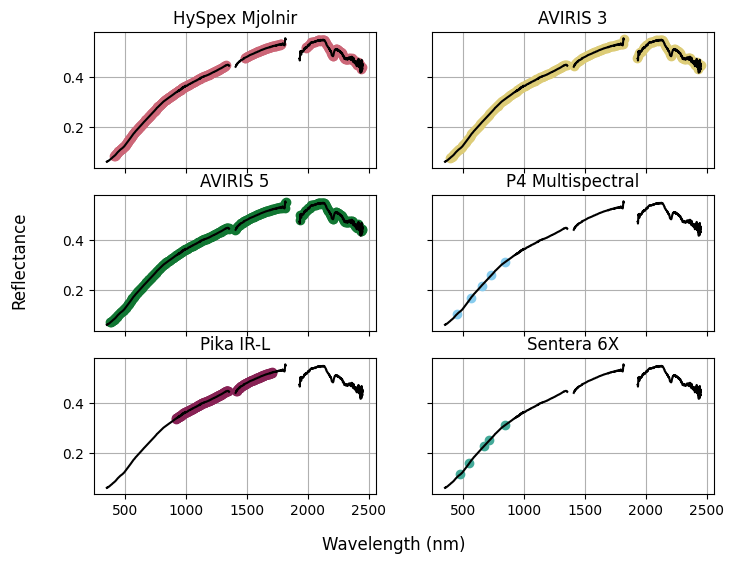

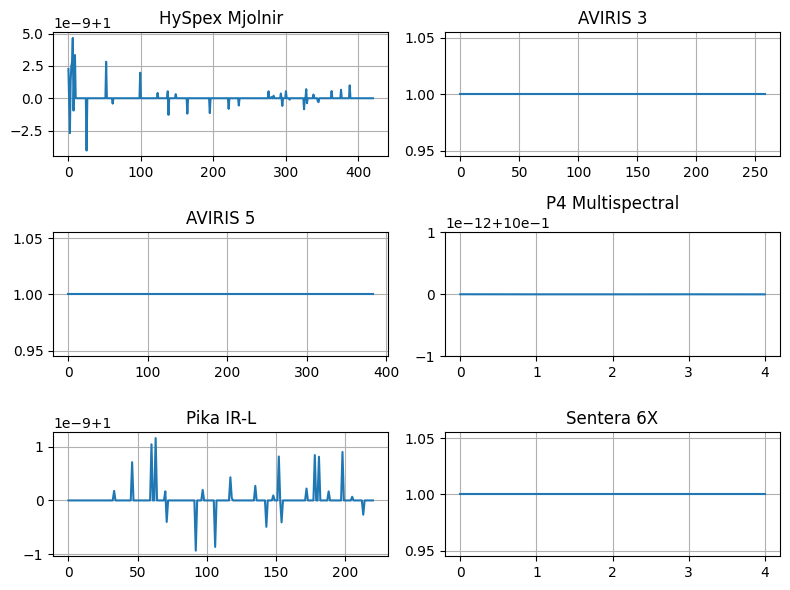

In [159]:
obs = 'Jul14-blue-1-repeated00000.asd.ref'

colors = [
    '#CC6677',

    '#DDCC77',
    '#117733',
    '#88CCEE',
    '#882255',
    '#44AA99',
    '#999933',
    '#AA4499',
    '#332288',
]

fig, axes = plt.subplots(3,2, sharex=True, sharey=True,
                         figsize=(8,6))
fig2, axes2 = plt.subplots(3,2, figsize=(8,6))

axes_flat = axes.flatten()
axes2_flat = axes2.flatten()

i=0

for instrument, spectra in resampled_data.items():
    print(instrument)

    ax = axes_flat[i]
    ax2 = axes2_flat[i]

    ax.set_title(instrument)
    ax.grid()
    
    ax2.set_title(instrument)
    ax2.grid()

    ax.plot(spectra_rfc.drop(columns=['Category']).loc[obs].rename(float), label='FieldSpec3', color='k', zorder=11)

    instrument_df = pd.read_excel(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\CommonSensors.xlsx",
                           sheet_name=instrument, index_col='Band Name')

    wavelength = instrument_df['Wavelength (nm)']

    reflectance = spectra.drop(columns=['Category']).loc[obs]

    ax.scatter(wavelength, reflectance, label=instrument, zorder=10, color=colors[i], marker='o')


    summed = resampled_data_sum[instrument].drop(columns=['Category']).loc[obs].rename('sum')
    ref_compare = pd.concat([reflectance, summed], axis=1)

    ref_compare = ref_compare.dropna()

    ref_compare['ratio'] = ref_compare.iloc[:,1] / ref_compare.iloc[:,0]
    mask = ~(ref_compare['ratio'] == 1)
    # ref_compare = ref_compare[mask]

    # ax2.scatter(ref_compare.iloc[:,0],ref_compare.iloc[:,1],
    #            label=instrument, s=1)
    # ax2.plot(np.arange(0,0.6,0.01), np.arange(0,0.6,0.01), color='k', alpha=0.5)

    ax2.plot(ref_compare.reset_index()['ratio'])
    
    
    i+=1

fig.supxlabel('Wavelength (nm)')
fig.supylabel('Reflectance')

# axes2.plot(np.arange(0,0.6,0.01), np.arange(0,0.6,0.01), color='k', alpha=0.5)



plt.tight_layout()




plt.savefig(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled.png", dpi=300)



In [8]:
# SRF type data

resampled_data = {}

resampled_data['Sentinel-2A'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_Sentinel_2A.csv", index_col='Sample Name')

resampled_data['Sentinel-2B'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_Sentinel_2B.csv", index_col='Sample Name')

resampled_data['Sentinel-2C'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_Sentinel_2C.csv", index_col='Sample Name')

resampled_data['Landsat ETM+'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_Landsat_ETM.csv", index_col='Sample Name')

resampled_data['Landsat OLI-TIRS'] = pd.read_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_Landsat_OLI.csv", index_col='Sample Name')




Sentinel-2A
Sentinel-2B
Sentinel-2C
Landsat ETM+
Landsat OLI-TIRS


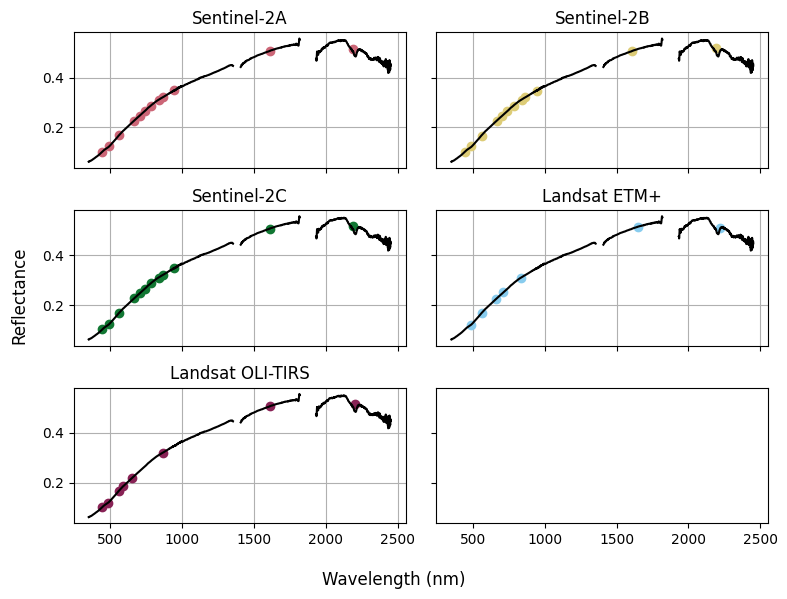

In [9]:
obs = 'Jul14-blue-1-repeated00000.asd.ref'

colors = [
    '#CC6677',
    '#DDCC77',
    '#117733',
    '#88CCEE',
    '#882255',
    '#44AA99',
    '#999933',
    '#AA4499',
    '#332288',
]

fig, axes = plt.subplots(3,2, sharex=True, sharey=True,
                         figsize=(8,6))

axes_flat = axes.flatten()

i=0

for instrument, spectra in resampled_data.items():
    print(instrument)

    ax = axes_flat[i]

    ax.set_title(instrument)
    ax.grid()

    ax.plot(spectra_rfc.drop(columns=['Category']).loc[obs].rename(float), label='FieldSpec3', color='k', zorder=11)

    instrument_df = pd.read_excel(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\SRFs\CommonSensors.xlsx",
                           sheet_name=instrument, index_col='Band Name')

    wavelength = instrument_df['Wavelength']

    reflectance = spectra.drop(columns=['Category']).loc[obs]

    ax.scatter(wavelength, reflectance, label=instrument, zorder=10, color=colors[i], marker='o')
    
    
    i+=1

fig.supxlabel('Wavelength (nm)')
fig.supylabel('Reflectance')

# axes2.plot(np.arange(0,0.6,0.01), np.arange(0,0.6,0.01), color='k', alpha=0.5)



plt.tight_layout()




plt.savefig(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\resampled_srf.png", dpi=300)



In [41]:
wavelength

Band Name
Band 1 – Coastal aerosol         443
Band 2 – Blue                    490
Band 3 – Green                   560
Band 4 – Red                     665
Band 5 – Vegetation red edge     705
Band 6 – Vegetation red edge     740
Band 7 – Vegetation red edge     783
Band 8 – NIR                     842
Band 8A – Narrow NIR             865
Band 10 – SWIR – Cirrus         1375
Band 11 – SWIR                  1610
Band 12 – SWIR                  2190
Name: Wavelength, dtype: int64

In [42]:
reflectance

S2A_SR_AV_B1     0.101730
S2A_SR_AV_B2     0.124863
S2A_SR_AV_B3     0.167369
S2A_SR_AV_B4     0.226025
S2A_SR_AV_B5     0.246551
S2A_SR_AV_B6     0.265367
S2A_SR_AV_B7     0.287513
S2A_SR_AV_B8     0.308466
S2A_SR_AV_B8A    0.320552
S2A_SR_AV_B9     0.347997
S2A_SR_AV_B10    0.000257
S2A_SR_AV_B11    0.507599
S2A_SR_AV_B12    0.514185
Name: Jul14-blue-1-repeated00000.asd.ref, dtype: float64

In [38]:
src_wl

Index([ 350,  351,  352,  353,  354,  355,  356,  357,  358,  359,
       ...
       2491, 2492, 2493, 2494, 2495, 2496, 2497, 2498, 2499, 2500],
      dtype='int64', length=2151)

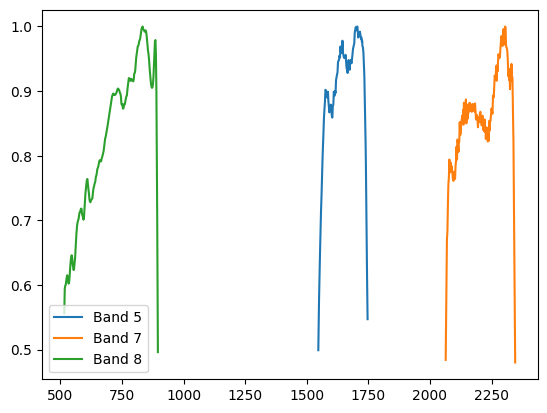

In [51]:
filename=r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\L7_ETM_interp.xlsx"

b5 = pd.read_excel(filename, sheet_name='B5', index_col='Wavelength')
b7 = pd.read_excel(filename, sheet_name='B7', index_col='Wavelength')
b8 = pd.read_excel(filename, sheet_name='B8', index_col='Wavelength')

wavelengths = pd.Series(index=src_wl, data=src_wl.to_list())

df = pd.concat([wavelengths,b5,b7,b8], axis=1)
df.drop(columns=[0], inplace=True)
df = df.interpolate(method='index',limit_area="inside")

plt.plot(df['Band 5'].index, df['Band 5'].values, label='Band 5')
plt.plot(df['Band 7'].index, df['Band 7'].values, label='Band 7')
plt.plot(df['Band 8'].index, df['Band 8'].values, label='Band 8')

plt.legend()

df = df.fillna(0)

df.to_csv(r"C:\Users\nmmas\OneDrive - Desert Research Institute\Soil Reflectance\Applied Remote Sensing Project\L7_ETM_interp.csv")